# EDA

Este notebook resume los analisis exploratorios principales del dataset de demanda electrica. El objetivo es entender la estructura de los perfiles diarios y detectar patrones relevantes para el modelo generativo condicionado.

In [1]:
%load_ext autoreload
%autoreload 2

In [35]:
from pathlib import Path
import os
import sys

project_root = Path.cwd()
if not (project_root / "src").exists():
    project_root = project_root.parent

sys.path.append(str(project_root))

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib-cache")
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

from src.data_quality import build_quality_summary
from src.daily_demand import (
    build_daily_demand_features,
    get_peak_hour_distribution,
    load_daily_model_data,
    plot_average_daily_profile,
    plot_daily_energy_series,
    plot_month_hour_heatmap,
    plot_peak_hour_distribution,
    plot_profile_by_day_type,
    summarize_by_day_type,
    summarize_by_month,
    summarize_daily_demand,
)
from src.shape_level import (
    get_pca_summary,
    plot_energy_examples,
    plot_normalized_profile_by_day_type,
    plot_raw_pc1_vs_energy,
    plot_shape_pca_components,
    summarize_shape_level,
)
from src.calendar_analysis import (
    plot_energy_by_month,
    plot_energy_by_weekday,
    plot_profile_by_month,
    plot_holiday_vs_workday,
    summarize_by_calendar,
)
from src.climate_analysis import (
    plot_demand_vs_temperature,
    plot_demand_vs_apparent_temp,
    plot_profile_by_temperature_tercile,
    plot_climate_by_month,
    summarize_climate_demand_correlation,
)
from src.relationships import (
    plot_pca_colored_by,
    plot_peak_hour_by_season,
    plot_demand_trend_by_year,
)

from src.social_events import (
    plot_covid_normalization,
    plot_election_profiles,
    plot_event_energy_residuals,
    plot_world_cup_profiles,
    summarize_annual_normalization,
    summarize_covid_periods,
    summarize_election_events,
    summarize_world_cup_events,
)

from src.outliers import (
    build_outlier_features,
    plot_outlier_score_timeline,
    plot_ramp_outlier_detail,
    plot_top_outlier_profiles,
    summarize_extreme_days_by_metric,
    summarize_outlier_counts,
    summarize_peak_hour_outliers,
    summarize_top_outlier_days,
)


## 1. Calidad del dataset

Antes de analizar patrones de consumo, verificamos que los datasets diarios y horarios sean consistentes. Esta seccion busca confirmar que la base esta en condiciones de ser usada para el EDA y el modelado.

In [3]:
summary = build_quality_summary(project_root)

In [4]:
summary["missing_values"]

,dataset,rows,columns,missing_values
0,x_perfiles_diarios,1946,25,0
1,c_condiciones_diarias,1946,16,0
2,dataset_base_horario,46704,6,0
3,clima_efectivo_horario,46704,6,0


In [5]:
summary["value_ranges"]

,variable,min,max
0,demanda_mwh,9281.924,28094.100000
1,X_demanda_min,9281.924,28094.100000
2,temp_ef,-0.879,38.345000
3,humedad_ef,17.710,96.260000
4,viento_ef,1.860,31.657000
5,sensacion_ef,-4.516,39.331000
6,grado_calor,0.000,9.890583
7,grado_frio,0.000,12.235250


### Resultados principales

- El dataset diario de demanda `X` tiene 1.946 filas y 25 columnas: una fecha y 24 valores horarios de demanda.
- El dataset condicional `C` tiene 1.946 filas y 16 columnas: fecha, calendario y variables climaticas diarias.
- Los datasets horarios de demanda y clima tienen 46.704 filas cada uno, lo que coincide con 1.946 dias por 24 horas.
- El periodo cubierto va desde 2021-01-01 hasta 2026-04-30.
- No hay dias faltantes en el rango observado.
- Todos los dias tienen exactamente 24 registros horarios tanto en demanda como en clima.
- No se detectaron duplicados a nivel fecha-hora.
- No hay valores nulos en `X`, `C`, demanda horaria ni clima horario.
- Las fechas de `X` y `C` estan perfectamente alineadas.
- El dia bisiesto 2024-02-29 esta presente.
- La demanda horaria va de 9.281,924 MWh a 28.094,100 MWh.
- Las variables climaticas no muestran valores imposibles: la temperatura efectiva va de -0,879 C a 38,345 C, y la humedad efectiva va de 17,710% a 96,260%.
- El promedio diario de energia fue mayor en los primeros 30 dias de 2023 que en los ultimos 30 dias de 2022. Esto no alcanza por si solo para afirmar un problema de empalme, porque enero tiene un comportamiento estacional propio asociado al verano.
- En esta seccion trabajamos solo con los CSV ya preparados para el proyecto. Los Excel originales quedan como fuentes crudas y no son necesarios para correr el EDA inicial.

## 2. Demanda diaria

En esta seccion analizamos la demanda como perfiles diarios de 24 horas. El objetivo es describir el nivel de consumo, la forma promedio del perfil horario y las diferencias principales por calendario.

In [6]:
x_profiles, conditions = load_daily_model_data(project_root)
daily_demand = build_daily_demand_features(x_profiles, conditions)

daily_summary = summarize_daily_demand(daily_demand)
monthly_summary = summarize_by_month(daily_demand)
day_type_summary = summarize_by_day_type(daily_demand)
peak_hour_distribution = get_peak_hour_distribution(daily_demand)

daily_summary

,mean,std,min,25%,50%,75%,max
energia_diaria_mwh,381524.35,52673.41,272305.63,344390.13,372857.10,416526.48,555081.40
demanda_media_mwh,15896.85,2194.73,11346.07,14349.59,15535.71,17355.27,23128.39
demanda_maxima_mwh,18698.94,2591.61,13661.95,16818.65,18186.27,20355.18,28094.10
demanda_minima_mwh,12987.48,1688.36,9281.92,11774.75,12696.35,14082.37,19542.80
hora_pico,19.72,3.59,1.00,21.00,21.00,21.00,23.00
hora_valle,6.12,2.02,4.00,5.00,6.00,7.00,24.00
amplitud_diaria_mwh,5711.46,1339.18,2364.36,4783.88,5482.65,6488.49,11004.20
factor_carga,0.85,0.03,0.72,0.83,0.85,0.87,0.93


La tabla resume las variables diarias derivadas a partir de las 24 horas de demanda. La energia diaria promedio es de 381,5 GWh y la demanda maxima diaria promedio es de 18.699 MWh.

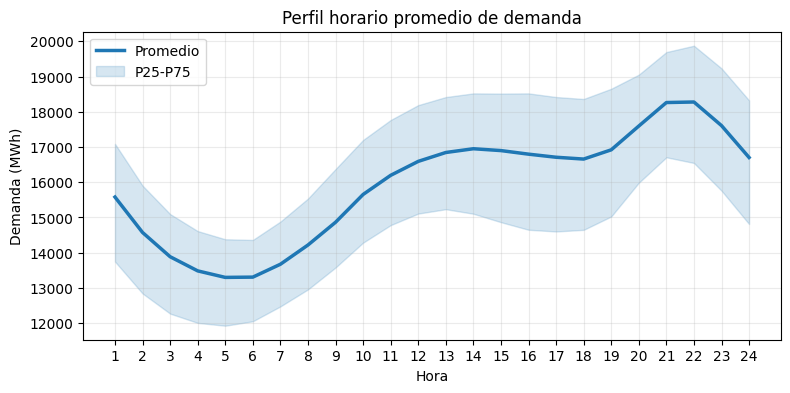

In [7]:
plot_average_daily_profile(daily_demand);

El perfil promedio muestra un valle durante la madrugada, con minimo alrededor de la hora 5, y un pico nocturno alrededor de las horas 21-22. Esta forma es importante para el modelo generativo: no alcanza con generar valores de demanda razonables, tambien hay que reproducir la estructura horaria del dia.

In [8]:
monthly_summary

,energia_media_gwh,demanda_maxima_media_mwh,hora_pico_mediana
mes,,,
1,421.74,20482.28,16.0
2,414.81,19997.79,17.0
3,384.30,18660.85,21.0
4,335.65,16489.00,21.0
5,365.73,18213.09,21.0
6,407.41,20286.21,21.0
7,410.73,20261.88,21.0
8,381.22,18825.36,21.0
9,350.13,17246.48,21.0


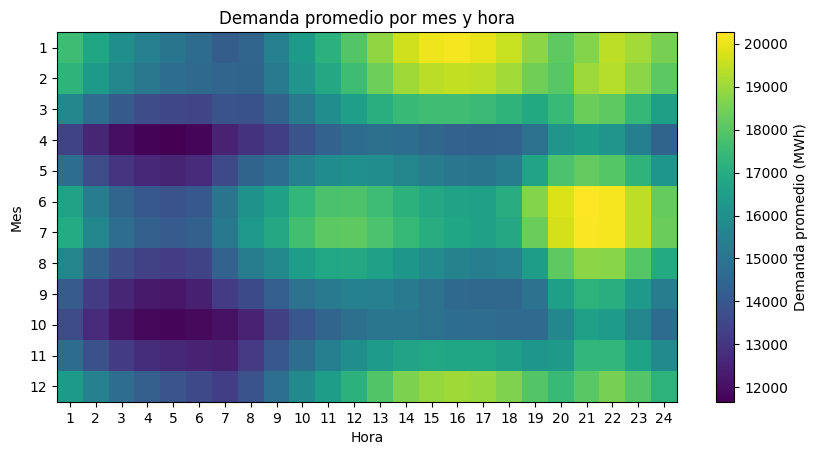

In [9]:
plot_month_hour_heatmap(daily_demand);

La demanda media diaria es mas alta en enero, febrero y julio, y mas baja en abril, octubre y septiembre. Esto sugiere una componente estacional marcada, consistente con mayor consumo en meses de calor y frio. Ademas, en enero, febrero y diciembre la mediana de la hora pico se adelanta hacia la tarde, mientras que en la mayoria de los meses se concentra a la noche.

In [10]:
day_type_summary

,dias,energia_media_gwh,demanda_maxima_media_mwh,factor_carga_medio
tipo_dia,,,,
habil,1309,396.39,19372.77,0.85
sabado,278,364.27,17591.41,0.86
domingo,278,339.16,17055.76,0.83
feriado,81,345.99,17250.28,0.84


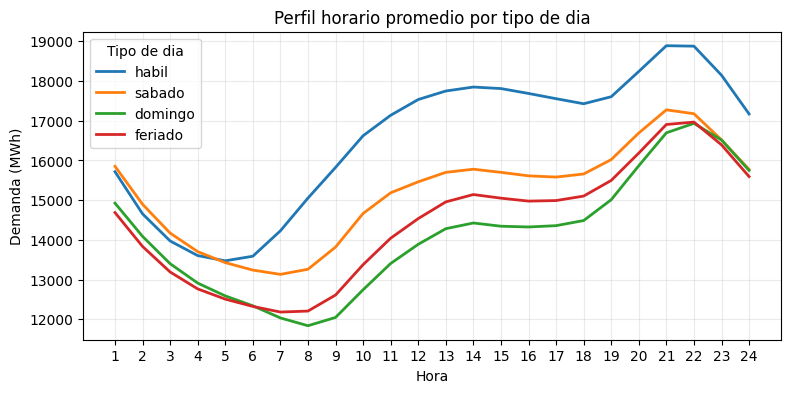

In [11]:
plot_profile_by_day_type(daily_demand);

Los dias habiles tienen mayor energia diaria promedio que sabados, domingos y feriados. Los domingos son el grupo de menor demanda media, aproximadamente 14% por debajo de los dias habiles. Esto confirma que el calendario no solo afecta el nivel de consumo, sino tambien la forma del perfil diario.

In [12]:
peak_hour_distribution.sort_values("dias", ascending=False).head(8)

,hora_pico,dias,porcentaje
8,21,1069,54.9
9,22,400,20.6
5,16,264,13.6
4,15,72,3.7
6,17,51,2.6
0,1,41,2.1
10,23,23,1.2
3,14,18,0.9


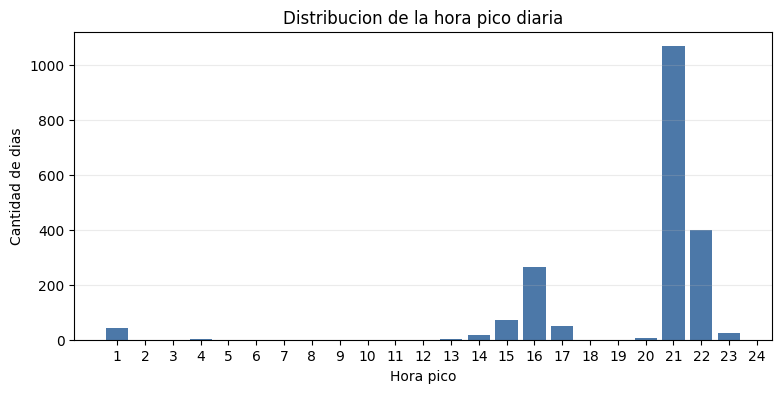

In [13]:
plot_peak_hour_distribution(daily_demand);

La hora pico diaria esta muy concentrada: la hora 21 explica 54,9% de los dias y la hora 22 explica 20,6%. En conjunto, tres de cada cuatro dias tienen su pico entre las 21 y las 22. Este patron deberia ser reproducido por los perfiles sinteticos.

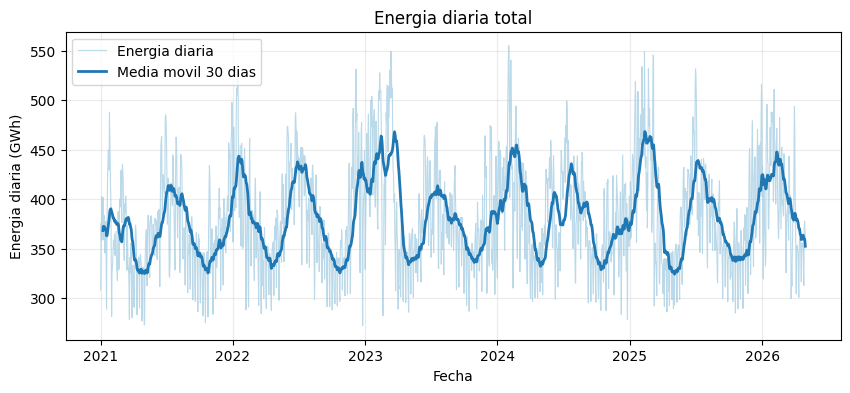

In [14]:
plot_daily_energy_series(daily_demand);

La serie temporal muestra variacion estacional y algunos dias extremos. El maximo de energia diaria se observa el 2024-02-01, con 555,1 GWh, mientras que el minimo ocurre el 2022-12-25, con 272,3 GWh. El minimo coincide con Navidad, por lo que parece un caso explicable por calendario. Tambien aparece el 2023-03-01 como dia de maxima amplitud diaria y mayor rampa horaria, por lo que conviene revisarlo luego junto con clima y eventos.

## 3. Forma vs nivel

Para un modelo generativo de perfiles diarios, no alcanza con analizar cuanta energia se consume por dia. Tambien importa la forma de la curva: en que horas cae, sube y alcanza el pico. En esta seccion separamos ambos efectos.

In [15]:
shape_level_summary = summarize_shape_level(daily_demand)
pca_summary = get_pca_summary(daily_demand)

shape_level_summary

,metric,value
0,cv_energia_diaria,0.1381
1,amplitud_relativa_media,0.3582
2,variabilidad_explicada_por_nivel,0.5869
3,pca_crudo_pc1_varianza,0.8652
4,pca_crudo_pc1_corr_energia_abs,0.9989
5,pca_forma_pc1_varianza,0.4614
6,pca_forma_pc2_varianza,0.3293
7,pca_forma_pc1_corr_energia_abs,0.3917


La energia diaria tiene un coeficiente de variacion de 13,8%, mientras que la amplitud intradiaria promedio equivale a 35,8% de la demanda media del dia. Es decir, hay variabilidad relevante tanto en el nivel diario como dentro de la forma horaria. Un modelo que solo capture el consumo total diario perderia una parte importante de la estructura del perfil.

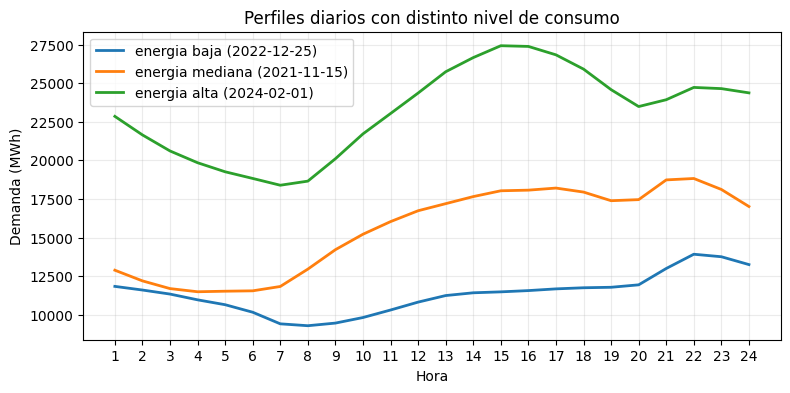

In [16]:
plot_energy_examples(daily_demand);

Los perfiles de baja, mediana y alta energia mantienen una estructura diaria reconocible, pero cambian mucho en escala. Esto sugiere que el nivel diario es una fuente dominante de variabilidad en los datos crudos.

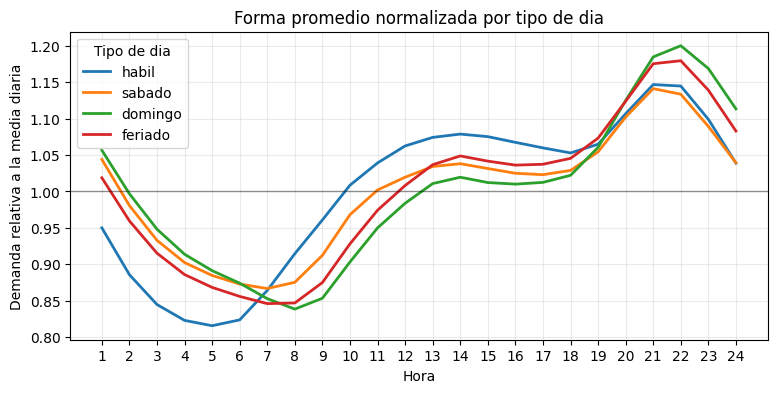

In [17]:
plot_normalized_profile_by_day_type(daily_demand);

Al dividir cada perfil por su propia demanda media diaria, se elimina el nivel y queda la forma relativa. Aun despues de esta normalizacion, los tipos de dia conservan diferencias visibles. Esto indica que el calendario afecta tambien la forma del perfil, no solo el total consumido.

In [18]:
pca_summary

,dataset,component,explained_variance,abs_corr_energia
0,demanda_cruda,1,0.8652,0.9989
1,perfil_normalizado,1,0.4614,0.3917
2,demanda_cruda,2,0.0653,0.0345
3,perfil_normalizado,2,0.3293,0.1686
4,demanda_cruda,3,0.0431,0.0308
5,perfil_normalizado,3,0.1567,0.2492
6,demanda_cruda,4,0.0196,0.0013
7,perfil_normalizado,4,0.0180,0.1678


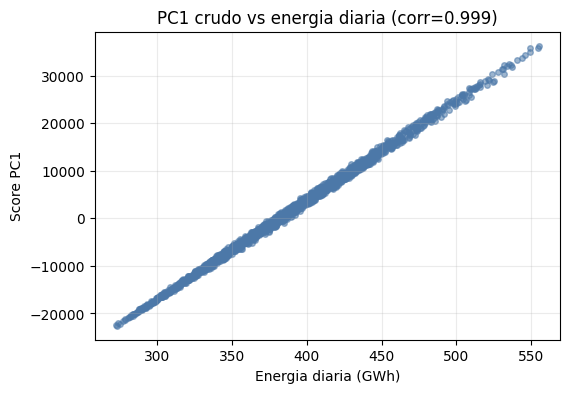

In [19]:
plot_raw_pc1_vs_energy(daily_demand);

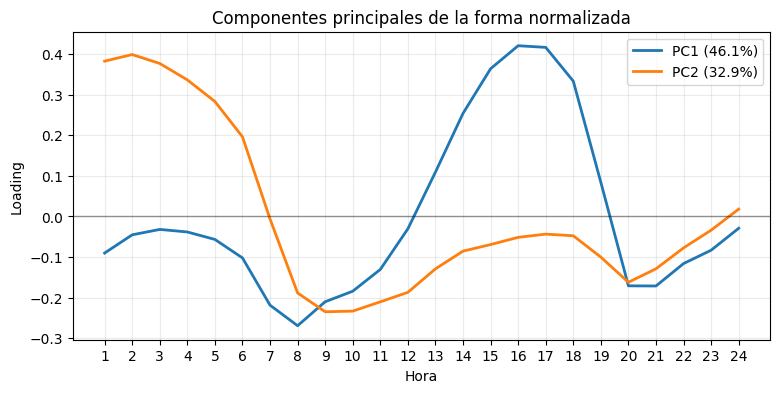

In [20]:
plot_shape_pca_components(daily_demand);

El resultado mas llamativo es que, sobre los perfiles crudos, la primera componente principal explica 86,5% de la varianza y tiene correlacion casi perfecta con la energia diaria (0,999 en valor absoluto). Por lo tanto, el primer PCA crudo representa principalmente nivel de consumo. Al repetir PCA sobre perfiles normalizados, las dos primeras componentes explican 79,1% de la variacion de forma y ya no representan solo escala.

### Preguntas a responder

**El modelo deberia aprender principalmente nivel, forma o ambas cosas?**  
Deberia aprender ambas. El nivel diario explica una parte importante de la variabilidad, pero la forma horaria tambien cambia de manera sistematica segun calendario y estacionalidad. Para el CVAE tiene sentido generar el perfil completo de 24 horas, y eventualmente comparar contra una version normalizada para estudiar forma pura.

**Los primeros componentes de PCA representan escala general o cambios de forma?**  
En perfiles crudos, la primera componente representa casi completamente escala general: explica 86,5% de la varianza y correlaciona 0,999 con la energia diaria. En perfiles normalizados, las componentes pasan a representar cambios de forma, por ejemplo diferencias entre horas de tarde, noche y madrugada.

**Que implica esto para el modelado?**  
Si se entrena PCA, GMM o autoencoder directamente sobre demanda en MWh, el modelo puede priorizar el nivel total y subestimar diferencias sutiles de forma. Por eso conviene evaluar resultados tanto en valores reales como en perfiles normalizados, especialmente al comparar curvas reales y sinteticas.

## 4. Calendario

El calendario es uno de los principales determinantes de la forma y el nivel de los perfiles diarios. Las rutinas laborales y sociales estructuran el consumo electrico a lo largo de la semana y del año. En esta seccion analizamos como varia la demanda segun el mes, el dia de semana y el tipo de dia. El objetivo es identificar que variables de calendario aportan informacion util al vector condicional `C`.

In [ ]:
calendar_summary = summarize_by_calendar(daily_demand, conditions)
calendar_summary[1]


,energia_media_mwh,demanda_max_media_mwh
tipo_dia,,
domingo,339163.165507,17055.762953
feriado,345985.883802,17250.282407
habil,396385.038288,19372.765968
sabado,364266.755993,17591.410759


In [28]:
calendar_summary[0]

,energia_media_mwh,demanda_max_media_mwh
mes,,
Ene,421740.061925,20482.277903
Feb,414810.162704,19997.790136
Mar,384297.247059,18660.848032
Abr,335649.572489,16489.000333
May,365725.824316,18213.089832
Jun,407409.650733,20286.206047
Jul,410733.872458,20261.881161
Ago,381220.034252,18825.359148
Sep,350131.991380,17246.481293


La tabla confirma que el tipo de día es el factor de calendario con mayor impacto 
en el nivel de consumo. Los días hábiles tienen una energía media de 396.385 MWh, 
mientras que los domingos son el grupo de menor consumo con 339.163 MWh, un 14,5% 
por debajo. Los feriados se ubican entre domingos y sábados, más cerca de los 
domingos que de los días hábiles. Por mes, enero y julio son los de mayor energía 
media (421.740 y 410.734 MWh respectivamente), mientras que abril y octubre son 
los de menor consumo (335.650 y 338.045 MWh). Este patrón en forma de U invertida 
doble refleja mayor demanda en los extremos térmicos del año.

### Energia diaria por mes

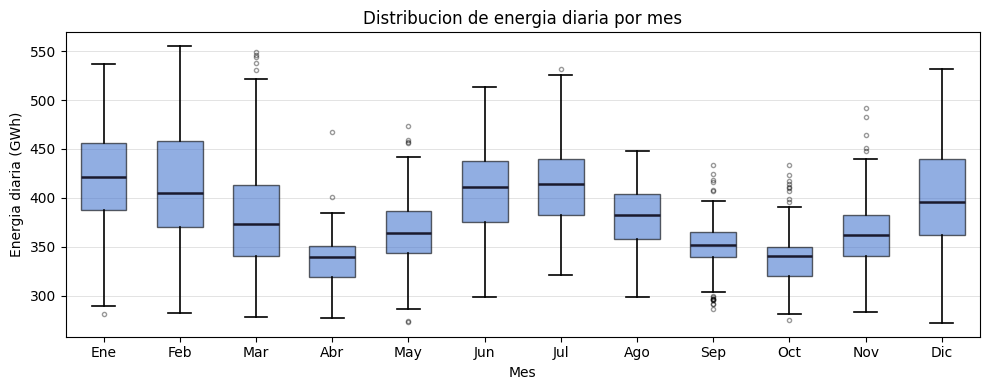

In [30]:
plot_energy_by_month(daily_demand, conditions)

El boxplot confirma la estacionalidad observada en la tabla. Los meses de verano 
(enero y febrero) y el pico invernal (junio y julio) tienen medianas claramente 
más altas que los meses de transición. Abril y octubre son los meses de menor 
demanda y también los de menor dispersión, lo que sugiere que en esos meses el 
clima es más uniforme y predecible. Marzo y septiembre muestran mayor variabilidad 
interna, con outliers hacia valores altos que probablemente corresponden a días 
de calor o frío inusual para esa época del año.

### Perfil horario promedio por mes

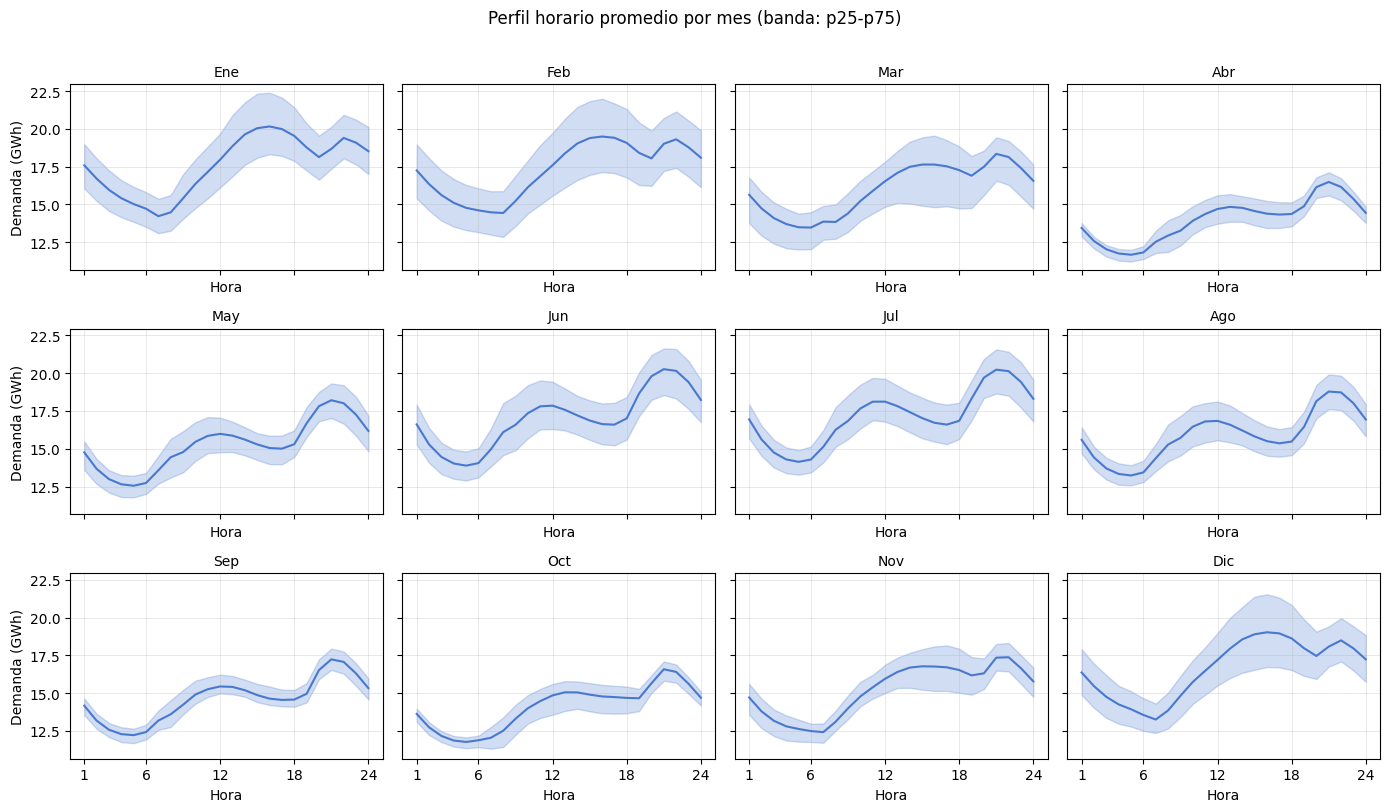

In [ ]:
plot_profile_by_month(daily_demand, conditions)

Los perfiles por mes revelan que el calendario no solo afecta el nivel sino también 
la forma de la curva diaria. En enero y febrero aparece un pico de tarde bien 
marcado alrededor de las 13-14 hs, que no se observa en los meses de invierno: 
ese pico corresponde al uso de aire acondicionado en las horas de mayor calor. 
En junio y julio el perfil tiene una forma más suave con un único pico nocturno 
pronunciado cerca de las 20-21 hs. Los meses de transición como abril, octubre 
y noviembre tienen perfiles más planos y con menor amplitud, coherente con menor 
necesidad de climatización. La banda p25-p75 es más ancha en enero, febrero y 
julio, lo que indica mayor variabilidad día a día dentro de esos meses, 
posiblemente por la mayor sensibilidad del consumo a las condiciones climáticas.

### Energia diaria por dia de semana

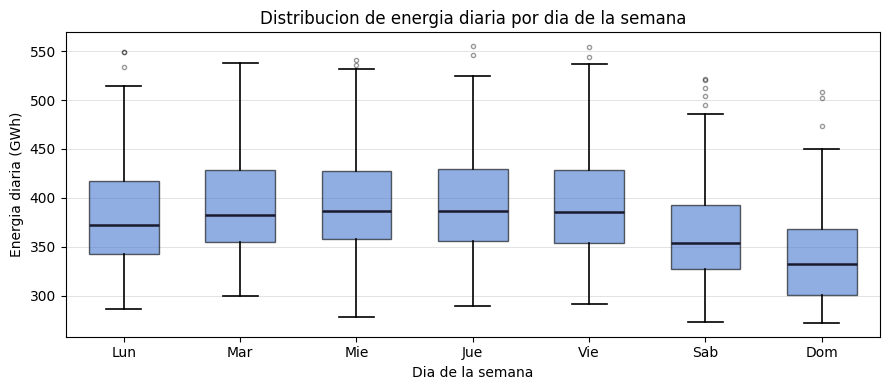

In [ ]:
plot_energy_by_weekday(daily_demand, conditions)

La energía diaria es relativamente estable de martes a viernes, con medianas 
similares alrededor de 380-385 GWh. El lunes muestra una mediana algo más baja, 
consistente con una reactivación gradual de la actividad después del fin de semana. 
El sábado cae claramente por debajo de los días hábiles, con una mediana cercana 
a 355 GWh, y el domingo es el día de menor consumo con mediana alrededor de 
335 GWh. La caída del fin de semana es abrupta entre viernes y sábado, y continúa 
el domingo. Los outliers altos presentes en casi todos los días corresponden 
probablemente a días de clima extremo que elevan el consumo independientemente 
del día de la semana.

### Feriados vs dias habiles

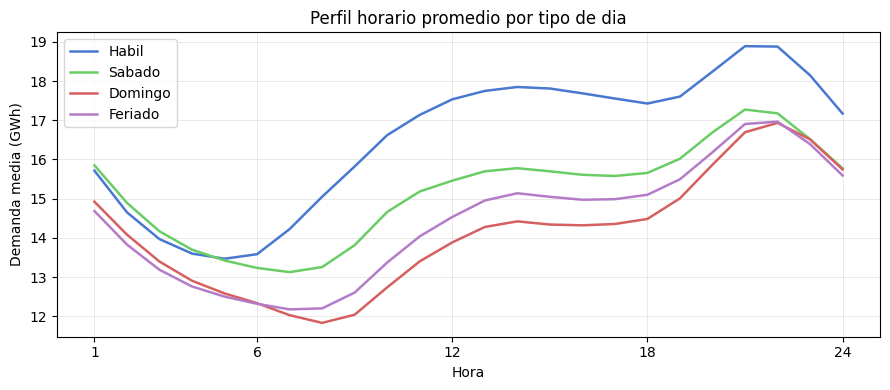

In [ ]:
plot_holiday_vs_workday(daily_demand, conditions)

El gráfico muestra que el tipo de día afecta tanto el nivel como la forma del 
perfil. Los días hábiles tienen el nivel más alto durante todo el día y mantienen 
una demanda sostenida entre las 10 y las 18 hs, que refleja la actividad 
industrial y comercial. Los sábados tienen un perfil intermedio: el nivel es menor 
que los hábiles pero mantienen algo de la meseta diurna. Los domingos y feriados 
tienen perfiles muy similares entre sí: nivel más bajo, sin meseta diurna y con 
un único pico nocturno cerca de las 21 hs. Esto sugiere que los feriados pueden 
modelarse junto con los domingos, o al menos que comparten el mismo tipo de 
estructura horaria. La diferencia entre hábiles y domingos no es solo de escala: 
la forma cambia, lo que confirma que el tipo de día debe entrar al vector 
condicional C.

### Preguntas a responder

**Los feriados se parecen más a domingos o tienen un patrón propio?**  
Los feriados se parecen más a domingos que a días hábiles, tanto en nivel 
(339.163 vs 345.986 MWh) como en forma del perfil horario. La diferencia entre 
feriados y domingos es pequeña comparada con la diferencia entre cualquiera de 
los dos y los días hábiles. Para el modelo, tiene sentido tratarlos como una 
categoría separada pero reconociendo su similitud con el domingo.

**Hay estacionalidad mensual fuerte?**  
Sí. La diferencia entre el mes de mayor energía media (enero, 421.740 MWh) y 
el de menor (abril, 335.650 MWh) es de 86.090 MWh, equivalente a un 25,6% del 
valor mínimo. Esa diferencia es lo suficientemente grande como para que el mes 
o la estación sean variables necesarias en C.

**Enero y febrero se comportan distinto por vacaciones?**  
Sí, pero no solo por vacaciones. Enero y febrero combinan dos efectos: menor 
actividad laboral y mayor uso de aire acondicionado. Ambos contribuyen a un 
perfil con pico de tarde que no aparece en otros meses. No es posible separar 
ambos efectos solo con este análisis.

**El calendario explica cambios de forma o principalmente cambios de nivel?**  
Ambos. El tipo de día cambia claramente la forma del perfil: los días hábiles 
tienen meseta diurna y los domingos tienen un único pico nocturno. El mes cambia 
principalmente el nivel, pero también modifica la forma en los extremos 
estacionales, como el doble pico de verano.

## 5. Clima

Argentina tiene inviernos frios y veranos calurosos, por lo que la calefaccion y el aire acondicionado pueden modificar tanto el nivel como la forma del perfil diario. En esta seccion analizamos la relacion entre las variables climaticas diarias y la demanda, y evaluamos si la sensacion termica explica mejor el consumo que la temperatura real.

### Correlaciones clima-demanda

In [47]:
climate_corr = summarize_climate_demand_correlation(daily_demand, conditions)
climate_corr

,energia_diaria_mwh,demanda_maxima_mwh
variable_clima,,
grado_calor,0.647,0.627
grado_frio,0.326,0.392
dia_semana,-0.273,-0.278
mes,-0.211,-0.190
sensacion_min,0.192,0.117
sensacion_max,0.189,0.121
sensacion_media,0.187,0.116
temp_min,0.173,0.100
temp_max,0.172,0.110


La variable con mayor correlación con la demanda es `grado_calor` (r = 0,647 con 
energía diaria), seguida de `grado_frio` (r = 0,326). La asimetría entre ambas 
es notable: el calor tiene el doble de correlación que el frío, lo que sugiere 
que el aire acondicionado en verano tiene un efecto más fuerte sobre la demanda 
que la calefacción en invierno. Las temperaturas y sensaciones térmicas muestran 
correlaciones lineales bajas (alrededor de 0,17-0,19), lo que no significa que 
no sean relevantes — la relación con la demanda no es lineal sino en forma de U, 
como se verá en los gráficos siguientes. La amplitud térmica diaria tiene 
correlación casi nula, lo que indica que la variación de temperatura dentro del 
día no aporta información adicional más allá del nivel medio. El viento y la 
humedad tienen correlaciones negativas pequeñas y probablemente no justifican 
su inclusión como variables independientes en C.

### Distribucion del clima por mes

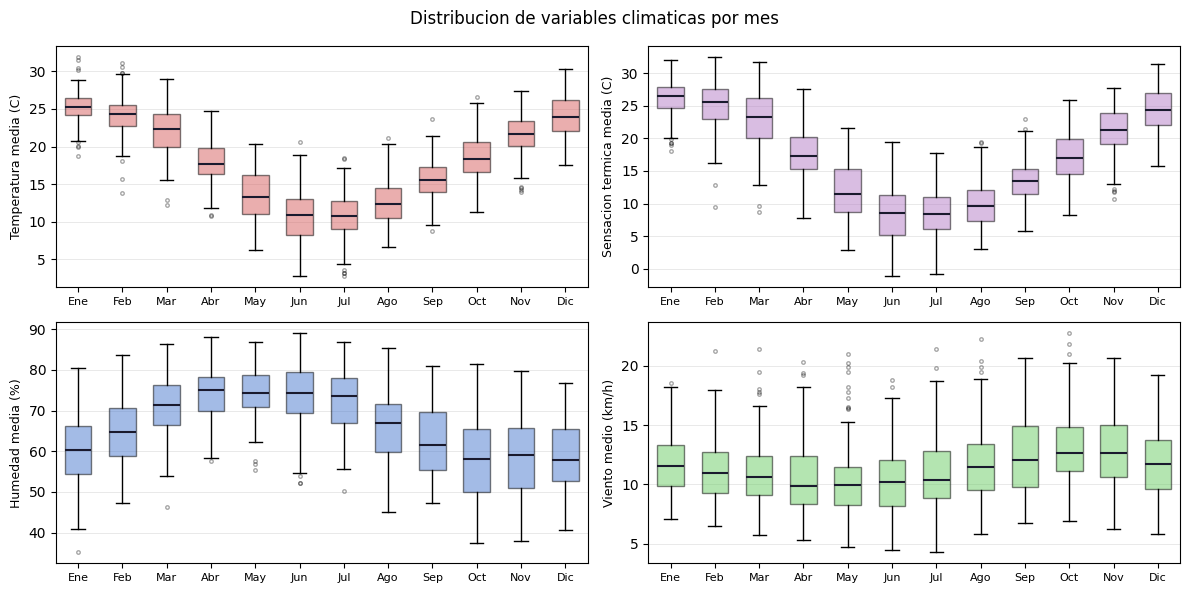

In [48]:
plot_climate_by_month(conditions)

La temperatura media sigue un patrón estacional claro: los meses de verano 
(enero y febrero) tienen medianas alrededor de 25 °C, mientras que junio y julio 
caen a aproximadamente 11 °C. La sensación térmica acompaña ese patrón pero 
con mayor dispersión en los meses de verano, posiblemente por el efecto de la 
humedad. La humedad media es más alta en invierno (junio-agosto, alrededor de 
75%) y más baja en primavera y verano (septiembre-diciembre, alrededor de 60%), 
lo que es consistente con el clima de la región pampeana. El viento no muestra 
estacionalidad marcada y tiene alta variabilidad intra-mensual en todos los meses, 
lo que es coherente con su baja correlación con la demanda observada en la tabla 
anterior.

### Demanda diaria vs temperatura

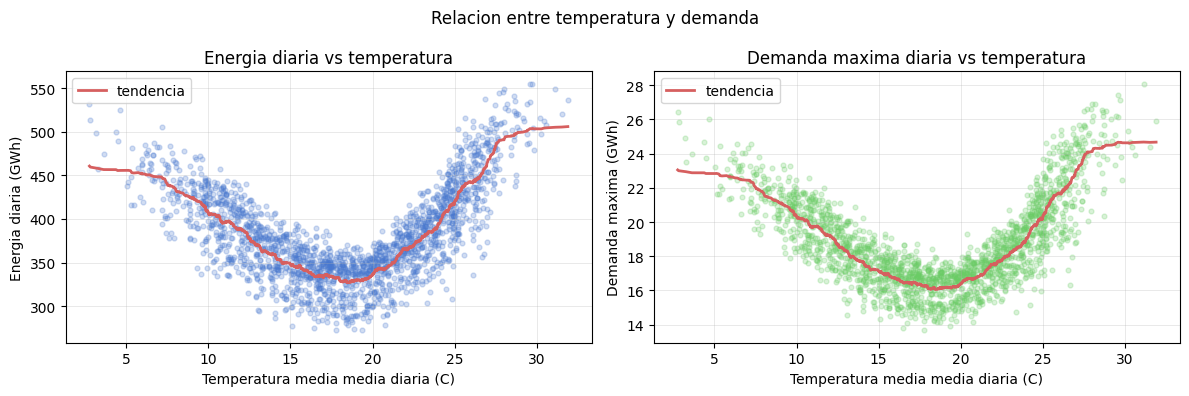

In [49]:
plot_demand_vs_temperature(daily_demand, conditions)

La relación entre temperatura media diaria y demanda tiene forma de U con mínimo 
alrededor de los 18-20 °C. Por debajo de ese umbral la demanda sube a medida que 
baja la temperatura, reflejando el uso de calefacción. Por encima, la demanda 
sube a medida que sube la temperatura, reflejando el uso de aire acondicionado. 
El brazo caluroso de la U es más pronunciado que el brazo frío, consistente con 
la mayor correlación de `grado_calor` observada en la tabla. La dispersión es 
considerablemente mayor en temperaturas altas, lo que indica que en días calurosos 
otros factores — como el día de la semana o la humedad — explican una parte 
importante de la variabilidad residual.

### Temperatura real vs sensacion termica como predictor

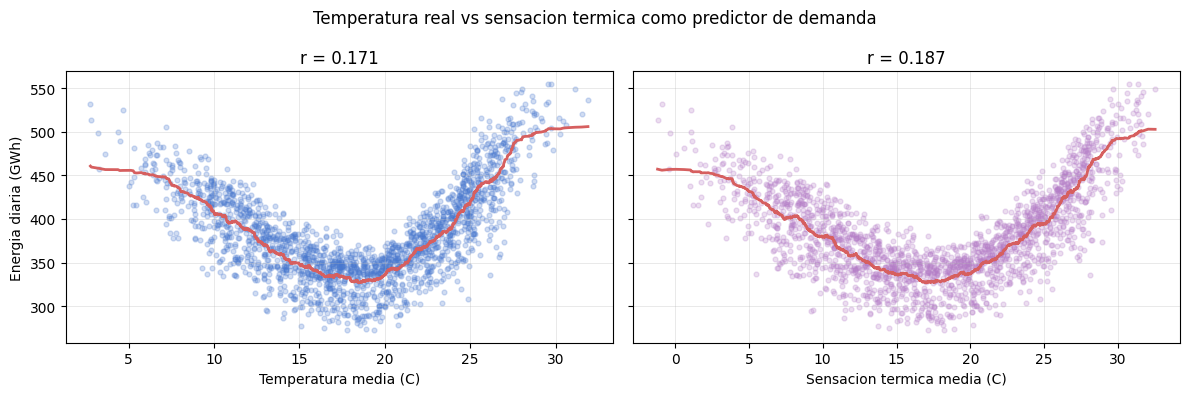

In [50]:
plot_demand_vs_apparent_temp(daily_demand, conditions)

Las curvas de tendencia de temperatura real (r = 0,171) y sensación térmica 
(r = 0,187) son prácticamente idénticas en forma, y la diferencia en correlación 
lineal es marginal. Sin embargo, la correlación lineal es un indicador limitado 
aquí porque la relación no es lineal. Visualmente, la nube de puntos tiene una 
dispersión similar en ambos casos. Dado que `grado_calor` y `grado_frio` ya 
capturan el efecto no lineal de la temperatura sobre la demanda con correlaciones 
mucho más altas, es probable que sean mejores candidatos para el vector 
condicional C que la temperatura o sensación térmica en forma directa.

### Perfil horario segun temperatura del dia

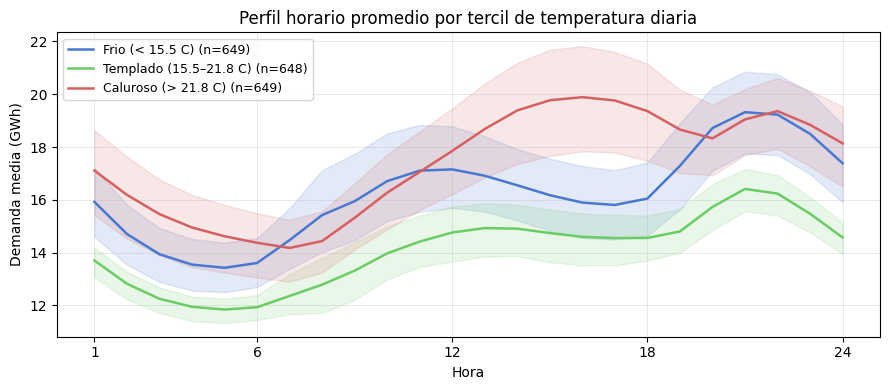

In [ ]:
plot_profile_by_temperature_tercile(daily_demand, conditions)

El gráfico muestra que la temperatura afecta tanto el nivel como la forma del 
perfil horario. Los días calurosos (más de 21,8 °C) tienen un pico de mediodía 
pronunciado alrededor de las 13-14 hs que no aparece en días fríos ni templados: 
ese pico corresponde al uso de aire acondicionado en las horas de mayor calor. 
Los días fríos tienen un perfil más plano durante el día y un pico nocturno 
similar al de los días calurosos pero de menor magnitud. Los días templados son 
los de menor demanda en todas las horas, sin pico de mediodía y con el nivel 
más bajo en el pico nocturno. Este resultado confirma que la temperatura no solo 
cambia el nivel del perfil sino también su forma, y justifica incluir alguna 
variable de temperatura en C para que el modelo pueda reproducir el doble pico 
de los días de verano.

### Preguntas a responder

**¿La relación entre temperatura y demanda tiene forma de U?**  
Sí, con mínimo alrededor de los 18-20 °C. Por debajo sube por calefacción y 
por encima sube por aire acondicionado.

**¿El calor afecta más que el frío?**  
Sí. `grado_calor` tiene el doble de correlación con la demanda que `grado_frio` 
(0,647 vs 0,326), y el brazo caluroso de la curva U es más pronunciado.

**¿La sensación térmica explica mejor la demanda que la temperatura real?**  
Marginalmente (r = 0,187 vs r = 0,171), pero la diferencia es pequeña. Las 
variables `grado_calor` y `grado_frio` capturan mejor el efecto no lineal 
y son mejores candidatas para C.

**¿Conviene usar clima diario agregado o clima horario como condición?**  
El clima diario agregado es suficiente como condición del modelo. La variable 
`grado_calor` tiene alta correlación con la demanda y es fácil de calcular 
a partir de la temperatura diaria. El clima horario agregaría complejidad sin 
una ganancia clara demostrada en este análisis.

## 6. Relaciones principales

En esta seccion integramos los analisis anteriores para estudiar las relaciones clave entre demanda, calendario y clima en el espacio de perfiles diarios. El PCA permite visualizar si los patrones de calendario y clima separan grupos de dias con perfiles distintos, lo que justifica su inclusion en el vector condicional `C`.

### Tendencia anual de la demanda

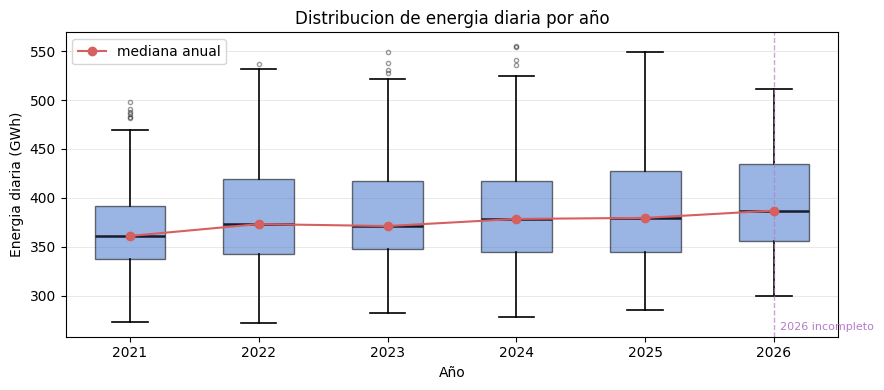

In [57]:
plot_demand_trend_by_year(daily_demand, conditions)

La mediana anual de energía diaria muestra una tendencia levemente creciente 
entre 2021 y 2026, pasando de aproximadamente 363 GWh a 385 GWh. El año 2021 
tiene la mediana más baja y la caja más estrecha del período, lo que podría 
reflejar efectos residuales de la pandemia sobre la actividad económica y la 
movilidad. A partir de 2022 la distribución se estabiliza con medianas similares 
entre sí. Los outliers superiores aparecen en todos los años y corresponden 
probablemente a días de clima extremo. El año 2026 figura como incompleto 
(solo hasta abril) y su caja es más alta que el promedio histórico para ese 
período, lo que es esperable dado que enero-abril concentra meses de verano 
con alta demanda. Por esta razón, 2026 no debe compararse directamente con 
los años completos.

### Hora del pico diario por estacion

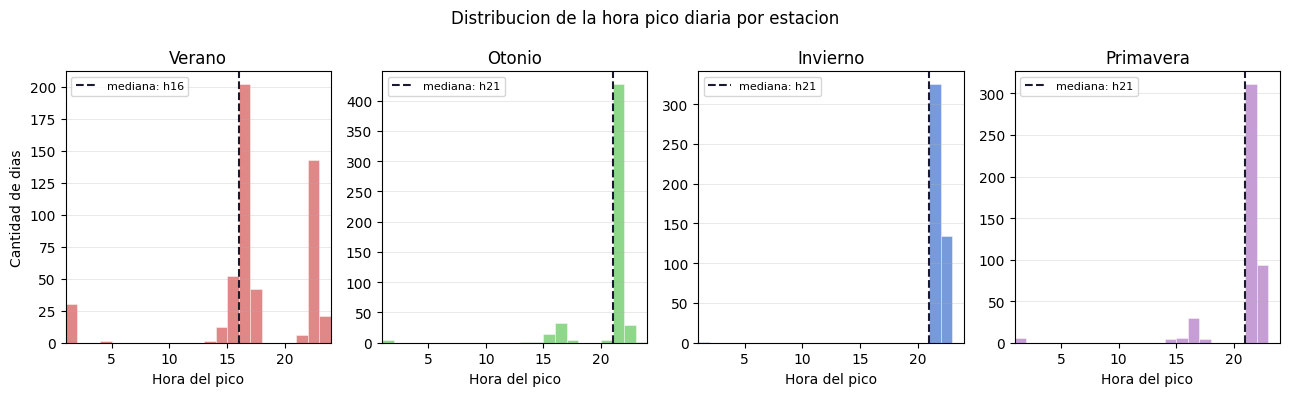

In [ ]:
plot_peak_hour_by_season(daily_demand, conditions)

La distribución de la hora pico muestra una diferencia marcada entre el verano 
y el resto del año. En otoño, invierno y primavera la concentración es casi 
total en la hora 21, con medianas coincidentes en ese valor y muy poca 
dispersión. En verano, en cambio, la distribución es bimodal: hay un pico 
dominante alrededor de las 16-17 hs, que corresponde a las horas de mayor 
calor y uso de aire acondicionado, y un segundo grupo alrededor de las 22-23 
hs. La mediana de verano cae en la hora 16, lo que contrasta completamente 
con las otras estaciones. Este resultado confirma que el mes o la estación 
deben entrar al vector condicional C: sin esa información, el modelo no podría 
distinguir entre un perfil de verano con pico de tarde y uno de invierno con 
pico nocturno.

### Espacio PCA coloreado por variables de contexto

Proyectamos los perfiles diarios sobre las dos primeras componentes principales y los coloreamos segun distintas variables de calendario y clima. Si una variable separa visualmente los grupos en el plano PCA, es probable que sea util como condicion del modelo.

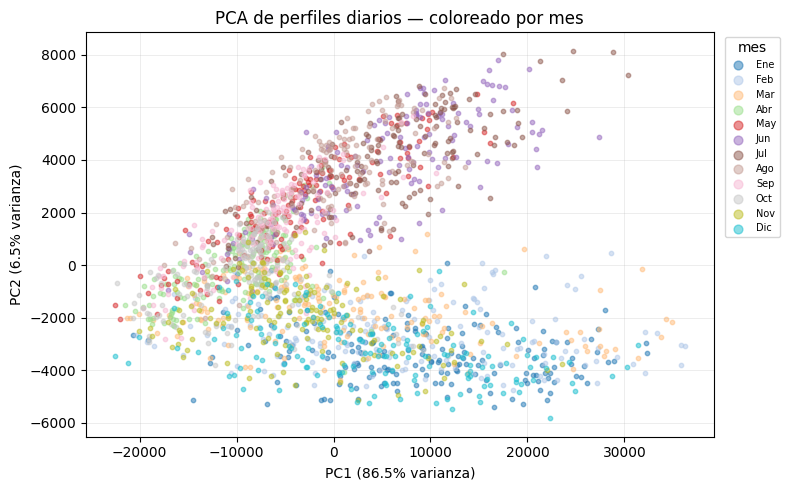

In [59]:
plot_pca_colored_by(daily_demand, conditions, color_by="mes")

En el espacio PCA los meses no forman clusters separados sino que se mezclan 
a lo largo de ambos ejes. Esto es esperable dado que PC1 representa 
principalmente el nivel de consumo (86,5% de varianza) y PC2 la forma (6,5%): 
cualquier mes puede tener días de alta o baja demanda dependiendo del clima 
y el calendario de esa semana. Sin embargo, se observa que los meses de 
invierno (junio, julio) y verano (enero, febrero) tienden a concentrarse 
en los extremos del eje PC1, mientras que los meses de transición (abril, 
octubre) se agrupan más hacia el centro-izquierda. Esto confirma que PC1 
captura la estacionalidad de nivel pero no es suficiente para separar meses 
individualmente.

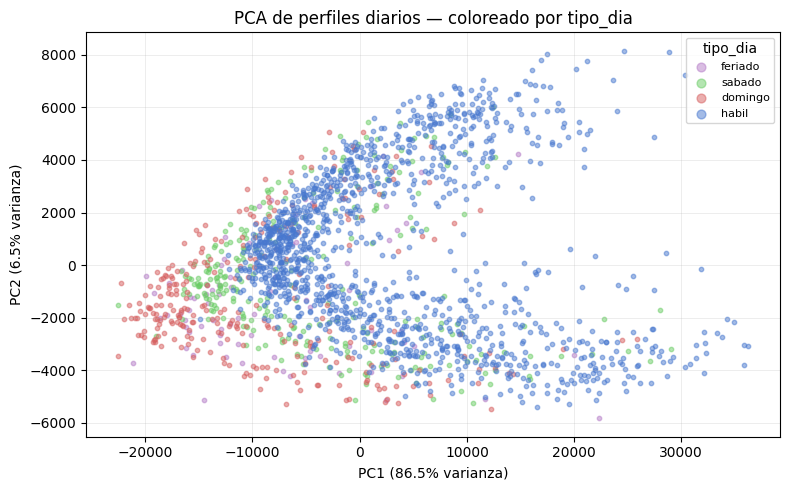

In [60]:
plot_pca_colored_by(daily_demand, conditions, color_by="tipo_dia")

El tipo de día sí produce una separación visible en el espacio PCA. Los días 
hábiles ocupan toda la extensión del eje PC1, incluyendo los valores más altos, 
mientras que domingos y feriados se concentran en la mitad izquierda, 
correspondiente a niveles de consumo más bajos. Los sábados quedan en una 
posición intermedia. Esta separación ocurre principalmente sobre PC1, lo que 
indica que el tipo de día afecta principalmente el nivel de consumo. La 
superposición entre grupos es considerable, especialmente entre días hábiles 
de bajo consumo y sábados de consumo alto, lo que sugiere que el tipo de día 
solo no determina el nivel: el clima del día también juega un rol importante.

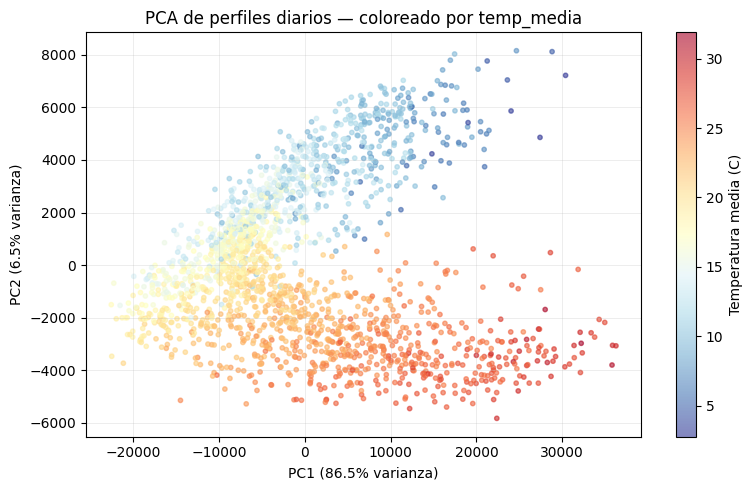

In [61]:
plot_pca_colored_by(daily_demand, conditions, color_by="temp_media_diaria")

El gradiente de temperatura sigue un patrón muy claro en el plano PCA. Los 
días fríos (azul oscuro, menos de 10 °C) se concentran en la parte superior 
derecha, con valores altos tanto en PC1 como en PC2. Los días calurosos (rojo, 
más de 25 °C) aparecen en la parte inferior derecha con PC1 alto y PC2 
negativo. Los días de temperatura media (amarillo, alrededor de 18-20 °C) 
quedan en la parte izquierda con PC1 bajo. Esta distribución es consistente 
con la curva en U observada antes: tanto el frío como el calor elevan el nivel 
de consumo (PC1 alto), pero lo hacen de maneras distintas que quedan separadas 
en PC2. Esto sugiere que PC2 captura parcialmente la diferencia entre perfiles 
de invierno y verano, más allá del nivel total.

### Preguntas a responder

**¿La demanda está más explicada por calendario, clima o tendencia temporal?**  
Los tres factores contribuyen, pero el clima y el calendario son los dominantes. 
La tendencia temporal es leve (aumento de unos 20 GWh en la mediana entre 2021 
y 2025). El clima explica los extremos de nivel y parte de la forma. El 
calendario explica la forma del perfil diario, especialmente la diferencia 
entre hábiles y fines de semana.

**¿Hay una tendencia creciente o decreciente entre 2021 y 2026?**  
Hay una tendencia creciente leve pero sostenida en la mediana anual. No es 
lo suficientemente pronunciada como para requerir modelado explícito de 
tendencia, pero conviene tenerla presente al evaluar perfiles generados.

**¿Qué variables deberían entrar al vector condicional C?**  
En base al EDA, las variables con mayor capacidad de caracterizar el perfil 
diario son: tipo de día (hábil, sábado, domingo, feriado), mes o estación, 
grado_calor y grado_frio. El mes captura la estacionalidad de nivel y la 
forma del pico, el tipo de día captura la estructura horaria diurna, y los 
grados capturan el efecto no lineal del clima sobre el nivel. Variables como 
humedad, viento y amplitud térmica tienen correlaciones bajas y no agregan 
información relevante según el análisis.

## 7. Eventos sociales argentinos

Como el dataset cubre 2021-2026, algunos eventos sociales argentinos pueden aparecer como dias atipicos. En esta seccion no los tratamos como variables centrales del modelo desde el inicio, sino como una forma de explicar residuos que el calendario y el clima no alcanzan a describir.

Para evitar conclusiones engañosas, cada fecha se compara contra dias similares: mismo mes, mismo dia de semana, misma condicion de feriado cuando hay suficientes controles, y temperatura media parecida. En feriados excepcionales generados por el propio evento, como el 20/12/2022, se relaja la condicion de feriado para comparar contra dias ordinarios equivalentes.


### COVID y normalizacion posterior

El dataset empieza en 2021, por lo que no captura la cuarentena estricta de 2020. Aun asi, permite mirar si 2021 quedo con un nivel de consumo distinto y si luego aparece una normalizacion progresiva.


In [ ]:
covid_period_summary = summarize_covid_periods(daily_demand, conditions)
covid_period_summary


,periodo,grupo,dias,energia_media_gwh,residuo_medio_pct,residuo_mediano_pct
0,Abr-may 2021,todos,61,341.05,-3.37,-3.35
1,Abr-may 2021,habil,43,352.08,-3.37,-3.43
2,Abr-may 2021,fin_de_semana,18,314.69,-3.35,-3.24
3,Restriccion 22-31 may 2021,todos,10,358.39,-2.41,-2.22
4,Restriccion 22-31 may 2021,habil,6,361.97,-4.03,-3.03
5,Restriccion 22-31 may 2021,fin_de_semana,4,353.01,0.03,0.39
6,Enero 2022 Omicron,todos,31,421.54,-0.53,-2.89
7,Enero 2022 Omicron,habil,21,434.13,-0.75,-2.89
8,Enero 2022 Omicron,fin_de_semana,10,395.08,-0.06,-2.78


In [ ]:
covid_annual_summary = summarize_annual_normalization(daily_demand, conditions)
covid_annual_summary


,anio,grupo,energia_media_gwh,residuo_medio_pct,residuo_mediano_pct,dias
0,2021,fin_de_semana,336.91,-3.23,-3.43,104
1,2021,habil,378.69,-2.76,-2.96,261
2,2022,fin_de_semana,349.35,-0.30,-0.68,105
3,2022,habil,392.67,-0.08,-0.95,260
4,2023,fin_de_semana,356.62,1.46,0.69,105
5,2023,habil,397.84,0.61,0.52,260
6,2024,fin_de_semana,354.44,0.86,-0.10,104
7,2024,habil,394.50,0.07,-0.63,262
8,2025,fin_de_semana,357.96,1.97,1.26,104
9,2025,habil,398.56,0.91,-0.18,261


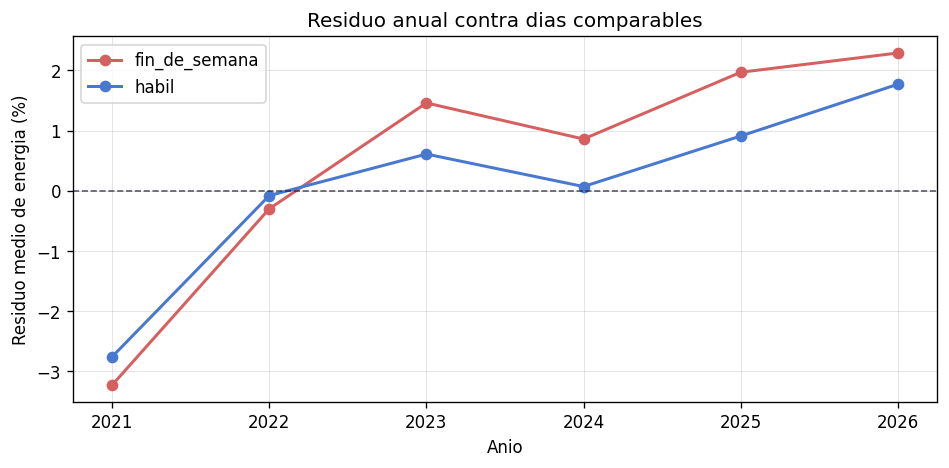

In [ ]:
plot_covid_normalization(daily_demand, conditions)


El consumo de 2021 queda por debajo de los años posteriores incluso al compararlo contra dias similares. En el resumen anual, los dias habiles de 2021 tienen un residuo medio de -2,76% y los fines de semana de -3,23%. Esto sugiere que 2021 conserva un efecto de menor actividad o movilidad, pero no aparece como una ruptura de forma completamente distinta.

En abril-mayo de 2021 el residuo medio es -3,37%, consistente con una demanda algo menor que la esperada. Durante la restriccion del 22 al 31 de mayo de 2021, la diferencia se concentra mas en dias habiles (-4,03%) que en fines de semana (0,03%). Enero de 2022, asociado a la ola de Omicron, no muestra una señal fuerte: queda apenas -0,53% contra controles comparables.

La lectura general es que hay una normalizacion progresiva: 2021 aparece bajo, 2022 queda casi alineado con lo esperado y desde 2023 los residuos promedio pasan a ser levemente positivos. Para el modelo, esto no justifica una variable COVID explicita, pero si conviene tener presente que 2021 puede contener perfiles de nivel algo deprimido.


### Mundial Qatar 2022

Analizamos los partidos de Argentina comparando el dia completo y, cuando corresponde, el bloque horario del partido contra dias similares. Esto permite separar el posible efecto social del partido del efecto fuerte de la temperatura de noviembre-diciembre.


In [ ]:
world_cup_summary = summarize_world_cup_events(daily_demand, conditions)
world_cup_summary[
    [
        "evento",
        "fecha",
        "hora_evento",
        "n_controles",
        "temp_media_c",
        "energia_gwh",
        "energia_esperada_gwh",
        "dif_energia_pct",
        "hora_pico",
        "dif_bloque_pct",
    ]
]


,evento,fecha,hora_evento,n_controles,temp_media_c,energia_gwh,energia_esperada_gwh,dif_energia_pct,hora_pico,dif_bloque_pct
0,Arabia Saudita,2022-11-22,07-09,9,18.95,335.15,352.74,-4.99,22,-9.55
1,Mexico,2022-11-26,16-18,5,26.39,423.75,385.68,9.87,16,14.62
2,Polonia,2022-11-30,16-18,12,24.24,448.21,392.79,14.11,14,4.76
3,Australia,2022-12-03,16-18,16,23.83,381.39,379.38,0.53,16,4.99
4,Paises Bajos,2022-12-09,16-19,6,29.52,486.95,451.20,7.92,15,8.09
5,Croacia,2022-12-13,16-18,14,23.70,423.85,399.69,6.04,15,3.38
6,Francia final,2022-12-18,12-15,13,22.45,325.81,348.28,-6.45,22,-6.74
7,Festejos seleccion,2022-12-20,dia completo,11,25.84,433.97,435.22,-0.29,17,NaN


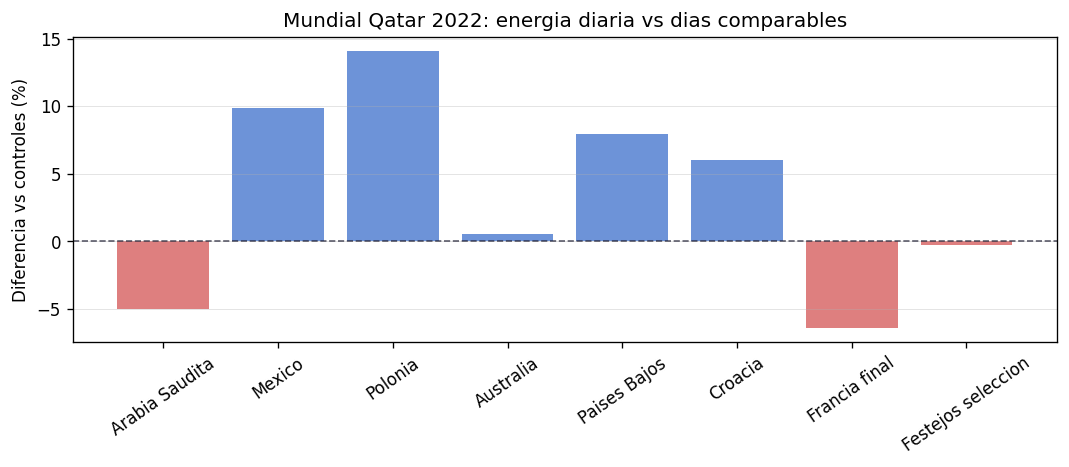

In [ ]:
plot_event_energy_residuals(
    world_cup_summary,
    "Mundial Qatar 2022: energia diaria vs dias comparables",
)


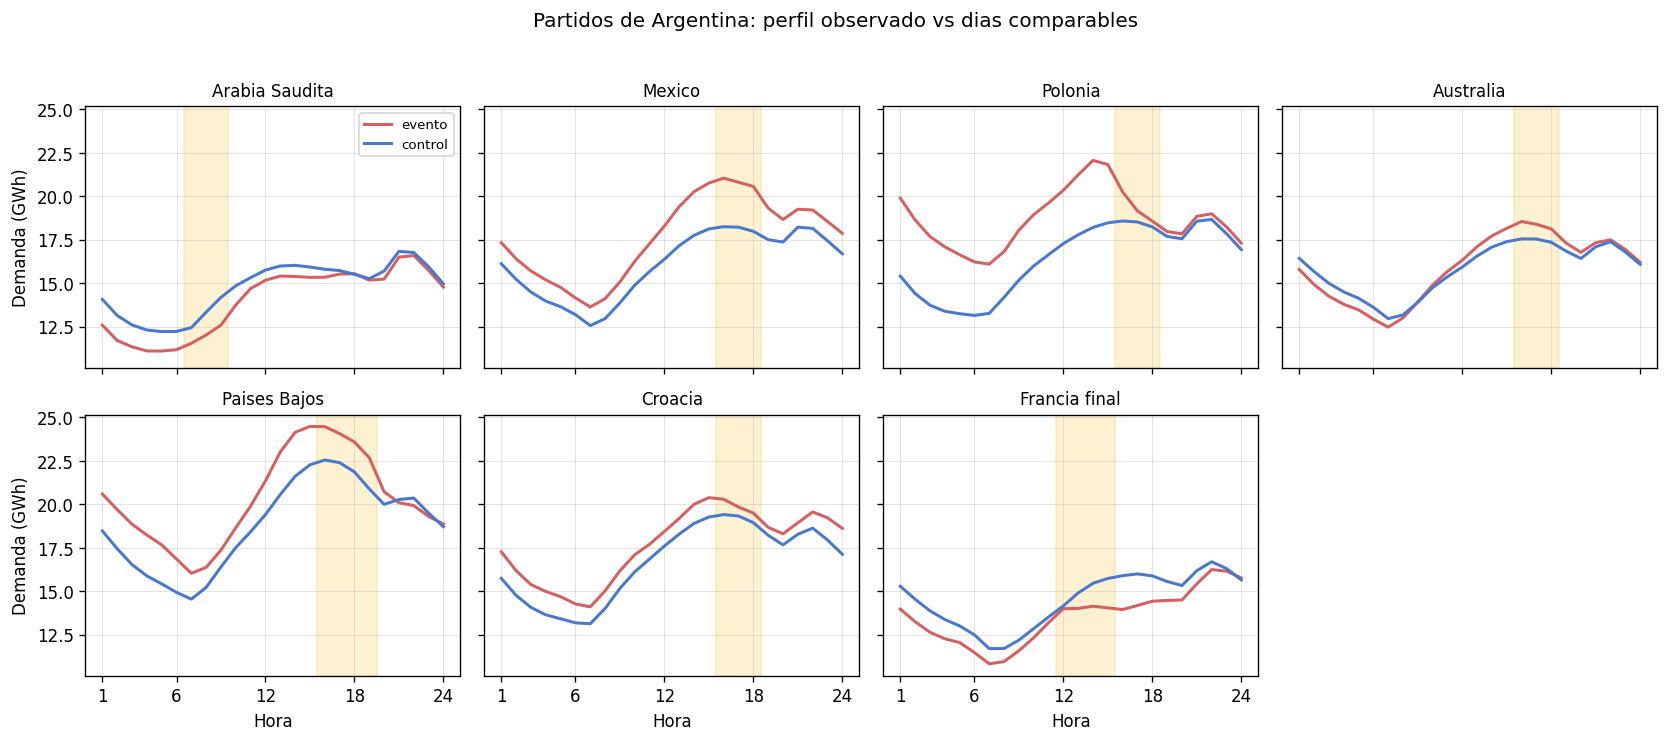

In [ ]:
plot_world_cup_profiles(daily_demand, conditions)


El resultado mas llamativo es que la final contra Francia si muestra una baja clara: el dia completo queda 6,45% por debajo de domingos de diciembre comparables y el bloque del partido queda 6,74% por debajo. Arabia Saudita tambien muestra una baja fuerte durante el partido (-9,55%), aunque al ser a las 7 de la mañana el efecto puede estar mezclado con rutinas de inicio del dia.

En cambio, los partidos de las 16 hs no muestran una caida sistematica. Mexico, Polonia, Paises Bajos y Croacia quedan por encima de sus controles, pero esos dias fueron calidos o muy calidos, por lo que la señal del partido queda mezclada con demanda por aire acondicionado. Paises Bajos, por ejemplo, tuvo 29,5 C de temperatura media y queda 7,92% arriba en energia diaria.

El 20/12/2022, dia de festejos y recibimiento de la seleccion, no aparece como outlier de energia diaria: queda -0,29% contra martes de diciembre con temperatura similar. Esto es importante porque era una fecha candidata a anomalia social fuerte, pero en el agregado diario no se diferencia demasiado de lo esperable por calendario y clima.


### Elecciones presidenciales 2023

Para las elecciones miramos los tres domingos electorales y separamos mañana, tarde, noche y dia posterior. La comparacion se hace contra domingos del mismo mes con temperatura parecida.


In [ ]:
election_summary = summarize_election_events(daily_demand, conditions)
election_summary[
    [
        "evento",
        "fecha",
        "n_controles",
        "temp_media_c",
        "energia_gwh",
        "energia_esperada_gwh",
        "dif_energia_pct",
        "dif_manana_pct",
        "dif_tarde_pct",
        "dif_noche_pct",
        "dif_dia_posterior_pct",
    ]
]


,evento,fecha,n_controles,temp_media_c,energia_gwh,energia_esperada_gwh,dif_energia_pct,dif_manana_pct,dif_tarde_pct,dif_noche_pct,dif_dia_posterior_pct
0,PASO,2023-08-13,16,10.73,365.19,347.18,5.19,9.06,1.64,2.37,1.88
1,General,2023-10-22,5,22.70,328.22,310.01,5.87,6.32,6.51,3.97,3.98
2,Balotaje,2023-11-19,16,21.13,306.90,310.21,-1.07,-1.53,1.74,1.33,-11.98


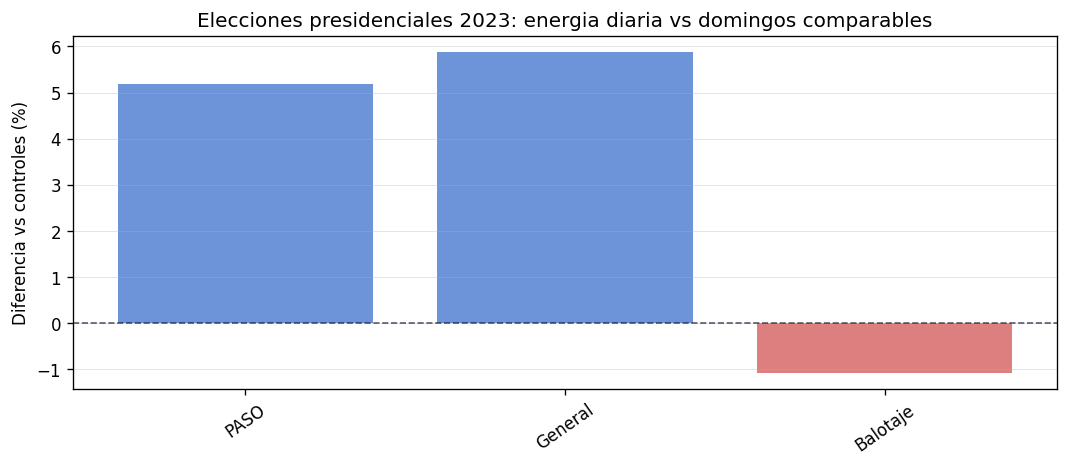

In [ ]:
plot_event_energy_residuals(
    election_summary,
    "Elecciones presidenciales 2023: energia diaria vs domingos comparables",
)


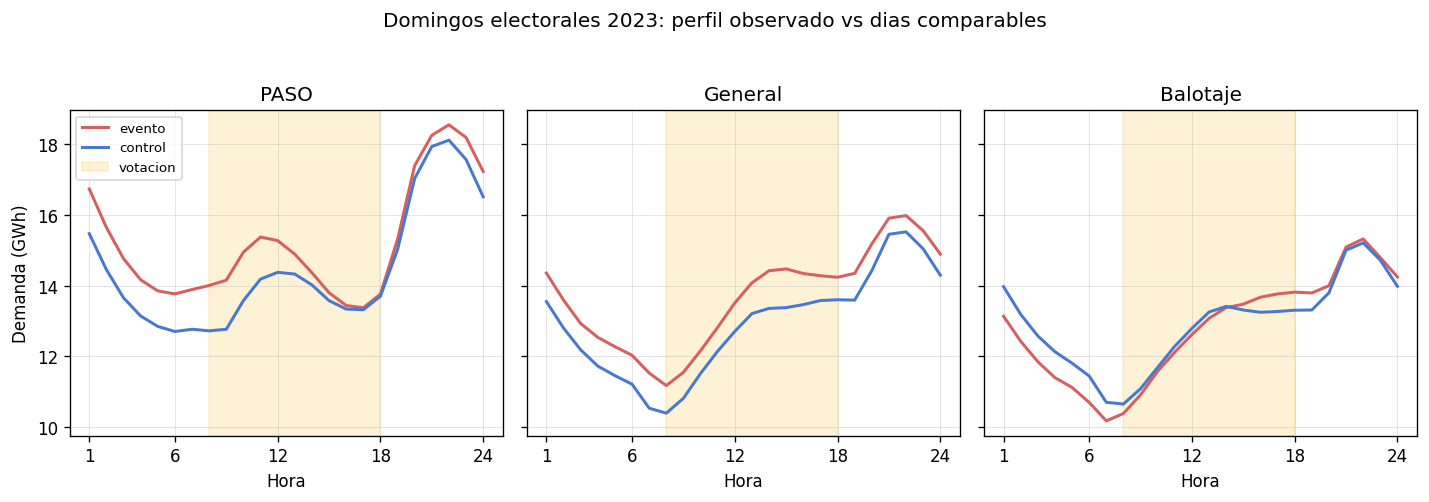

In [ ]:
plot_election_profiles(daily_demand, conditions)


Las elecciones muestran una señal mas debil que el Mundial. PASO y eleccion general quedan algo por encima de domingos comparables, con diferencias de 5,19% y 5,87% respectivamente. El balotaje, en cambio, queda practicamente normal (-1,07%).

La diferencia horaria tampoco es completamente consistente. En PASO aparece una suba de mañana (+9,06%), mientras que en la eleccion general la suba se reparte entre mañana y tarde (+6,32% y +6,51%). La noche electoral tiene diferencias mas chicas: +2,37% en PASO, +3,97% en general y +1,33% en balotaje. El dia posterior no muestra un patron estable; el valor bajo posterior al balotaje coincide con un feriado, por lo que no conviene atribuirlo directamente al evento electoral.

En conclusion, las elecciones pueden explicar pequeñas desviaciones en algunos domingos, pero no parecen generar un tipo de perfil tan marcado como para incorporarlas como condicion principal del modelo.


### Preguntas a responder

**2021 tiene perfiles distintos al resto?**  
Si, principalmente en nivel. Contra dias comparables, 2021 queda alrededor de 3% por debajo tanto en dias habiles como en fines de semana. No parece una forma horaria completamente nueva, sino una demanda general algo deprimida.

**Se observa una normalizacion progresiva?**  
Si. Los residuos pasan de valores negativos en 2021 a valores cercanos a cero en 2022 y levemente positivos desde 2023. La normalizacion no es abrupta, pero la tendencia es clara.

**Cambian mas los dias habiles que los fines de semana durante COVID?**  
En el promedio anual de 2021 cambian de manera parecida. En la ventana estricta del 22 al 31 de mayo de 2021, si se ve un efecto mas fuerte en dias habiles (-4,03%) que en fines de semana (0,03%).

**Durante los partidos del Mundial baja o sube la demanda?**  
No hay una respuesta unica. La final y Arabia Saudita muestran bajas durante el partido, pero varios partidos de las 16 hs quedan por encima de controles por efecto de dias calidos. El evento social existe, pero esta mezclado con clima.

**Hay cambio en la forma horaria del dia durante el Mundial?**  
Si en algunos partidos, especialmente en la final, donde el bloque del partido queda por debajo de lo esperado. Pero no aparece una forma comun a todos los partidos.

**La final tiene un comportamiento distinto al de otros domingos comparables?**  
Si. El dia completo queda 6,45% por debajo y el bloque del partido 6,74% por debajo de domingos comparables de diciembre.

**El dia de festejos aparece como outlier?**  
No. El 20/12/2022 queda practicamente igual al esperado (-0,29%) contra martes de diciembre con temperatura similar.

**Los domingos electorales se comportan distinto a domingos normales?**  
Solo parcialmente. PASO y eleccion general quedan cerca de 5-6% arriba, pero el balotaje queda normal. La evidencia es mixta.

**Hay cambios en la tarde por movilidad social?**  
La eleccion general muestra una tarde 6,51% por encima de controles, pero PASO y balotaje tienen cambios mucho menores. No alcanza para afirmar un patron general.

**Hay cambios en la noche por seguimiento de resultados?**  
Las diferencias nocturnas son chicas, entre 1% y 4%. No parecen ser el rasgo dominante de los domingos electorales.


## 9. Outliers y dias atipicos

En esta seccion buscamos dias atipicos sin asumir que sean errores. Un outlier puede ser informacion valiosa para el modelo si representa variabilidad real, por ejemplo calor extremo, frio extremo o una fecha especial. Por eso combinamos varios criterios: nivel diario, demanda maxima y minima, amplitud, rampas horarias, hora del pico y forma del perfil normalizado.

La regla de lectura es la misma que usamos para eventos: primero se identifica el extremo y despues se intenta explicarlo por calendario, clima o evento externo. Solo si no aparece una explicacion clara conviene revisarlo antes de decidir si entra al entrenamiento.


In [ ]:
outlier_features = build_outlier_features(daily_demand, conditions)
outlier_counts = summarize_outlier_counts(outlier_features)
outlier_counts


,metrica,outliers_abs,outliers_altos,outliers_bajos,score_max_abs,fecha_mas_extrema
0,energia diaria,4,4,0,3.69,2024-02-01
1,demanda maxima,7,7,0,4.15,2025-02-10
2,demanda minima,7,7,0,4.15,2024-02-08
3,amplitud diaria,8,8,0,4.56,2023-03-01
4,rampa horaria,4,4,0,16.49,2023-03-01
5,forma del perfil,43,43,0,18.73,2023-03-01


La mayor parte de los outliers de nivel son altos, no bajos. Con un umbral robusto de 3,5 aparecen 4 outliers de energia diaria, 7 de demanda maxima, 7 de demanda minima alta y 8 de amplitud diaria. Esto es coherente con lo visto en clima: los extremos superiores se concentran en dias de calor fuerte.

El caso mas llamativo no es el maximo de energia sino la rampa horaria. El 2023-03-01 tiene un score robusto de 16,49 en rampa y de 18,73 en forma del perfil, muy por encima del resto. Ese dia la demanda cae abruptamente despues del pico de la tarde, lo que no parece una variacion normal de consumo.


In [ ]:
extreme_days = summarize_extreme_days_by_metric(outlier_features)
extreme_days


,caso,fecha,tipo_dia,temp_media_c,energia_gwh,hora_pico,valor,score_robusto,explicacion,accion_modelado
0,energia minima,2022-12-25,domingo,19.37,272.31,22,272305.63,-2.04,Navidad,conservar como variabilidad real
1,energia maxima,2024-02-01,habil,29.57,555.08,15,555081.40,3.69,calor extremo,conservar como variabilidad real
2,demanda maxima,2025-02-10,habil,31.14,549.12,16,28094.10,4.15,calor extremo,conservar como variabilidad real
3,demanda minima,2022-12-25,domingo,19.37,272.31,22,9281.92,-2.07,Navidad,conservar como variabilidad real
4,amplitud maxima,2023-03-01,habil,27.01,478.36,16,11004.20,4.56,evento de suministro + calor extremo,etiquetar aparte / revisar
5,rampa maxima,2023-03-01,habil,27.01,478.36,16,6320.50,16.49,evento de suministro + calor extremo,etiquetar aparte / revisar
6,forma mas atipica,2023-03-01,habil,27.01,478.36,16,13.11,18.73,evento de suministro + calor extremo,etiquetar aparte / revisar


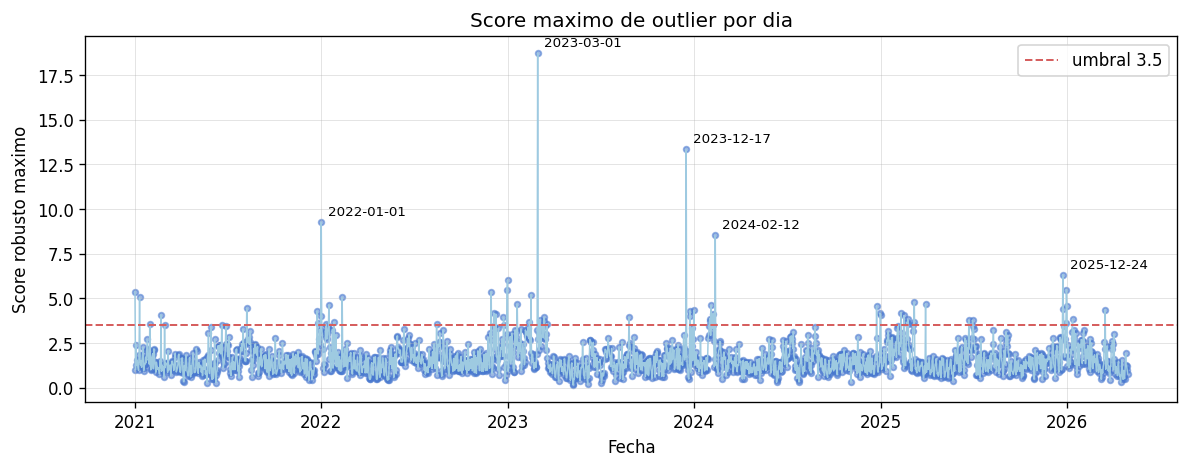

In [ ]:
plot_outlier_score_timeline(outlier_features)


La tabla de casos extremos muestra que los maximos de energia y demanda se explican por calor extremo: 2024-02-01 es el maximo de energia diaria con 555,08 GWh y 2025-02-10 tiene la mayor demanda horaria, 28.094 MWh, con temperatura media de 31,14 C. Estos dias no parecen errores: son ejemplos reales de demanda alta bajo condiciones termicas severas.

El minimo de energia diaria es 2022-12-25, con 272,31 GWh. Aunque en el calendario aparece como domingo, la explicacion natural es Navidad: bajo nivel de actividad, perfil mas residencial y demanda minima tambien muy baja. Este tipo de caso deberia conservarse si el modelo tiene informacion de calendario suficiente.


In [ ]:
top_outlier_days = summarize_top_outlier_days(outlier_features)
top_outlier_days


,fecha,tipo_dia,temp_media,temp_max,energia_gwh,hora_pico,max_rampa_abs_mwh,metric_principal,outlier_score,explicacion,accion_modelado
789,2023-03-01,habil,27.01,32.57,478.36,16,6320.50,forma del perfil,18.73,evento de suministro + calor extremo,etiquetar aparte / revisar
1080,2023-12-17,domingo,26.14,28.60,335.25,1,2627.60,forma del perfil,13.33,calor extremo + forma horaria atipica,revisar forma / posible etiqueta
365,2022-01-01,sabado,26.68,30.29,356.75,4,1159.16,forma del perfil,9.26,Anio Nuevo + calor extremo + forma horaria ati...,revisar forma / posible etiqueta
1137,2024-02-12,feriado,24.13,27.26,384.82,1,872.20,forma del perfil,8.54,feriado + forma horaria atipica,revisar forma / posible etiqueta
1818,2025-12-24,habil,27.00,32.14,453.74,16,1730.40,forma del perfil,6.32,Nochebuena + calor extremo,conservar como variabilidad real
730,2023-01-01,domingo,24.21,27.84,329.17,23,904.60,forma del perfil,6.03,Anio Nuevo + forma horaria atipica,revisar forma / posible etiqueta
729,2022-12-31,sabado,26.22,30.27,414.93,16,1444.82,forma del perfil,5.49,Fin de anio + calor extremo,conservar como variabilidad real
1825,2025-12-31,habil,30.27,35.90,497.93,15,2807.00,forma del perfil,5.48,Fin de anio + calor extremo + forma horaria at...,revisar forma / posible etiqueta
698,2022-11-30,habil,24.24,27.31,448.21,14,1579.25,forma del perfil,5.38,Mundial Qatar 2022 + forma horaria atipica,revisar forma / posible etiqueta
0,2021-01-01,feriado,24.86,30.66,308.46,23,1031.21,forma del perfil,5.37,feriado + Anio Nuevo + calor extremo + forma h...,revisar forma / posible etiqueta


In [ ]:
peak_hour_outliers = summarize_peak_hour_outliers(outlier_features)
peak_hour_outliers


,hora_pico,dias,porcentaje,categoria
0,1,41,2.1,menos frecuente
1,4,1,0.1,menos frecuente
2,13,2,0.1,menos frecuente
3,14,18,0.9,menos frecuente
4,15,72,3.7,menos frecuente
5,16,264,13.6,habitual
6,17,51,2.6,menos frecuente
7,20,5,0.3,menos frecuente
8,21,1069,54.9,habitual
9,22,400,20.6,habitual


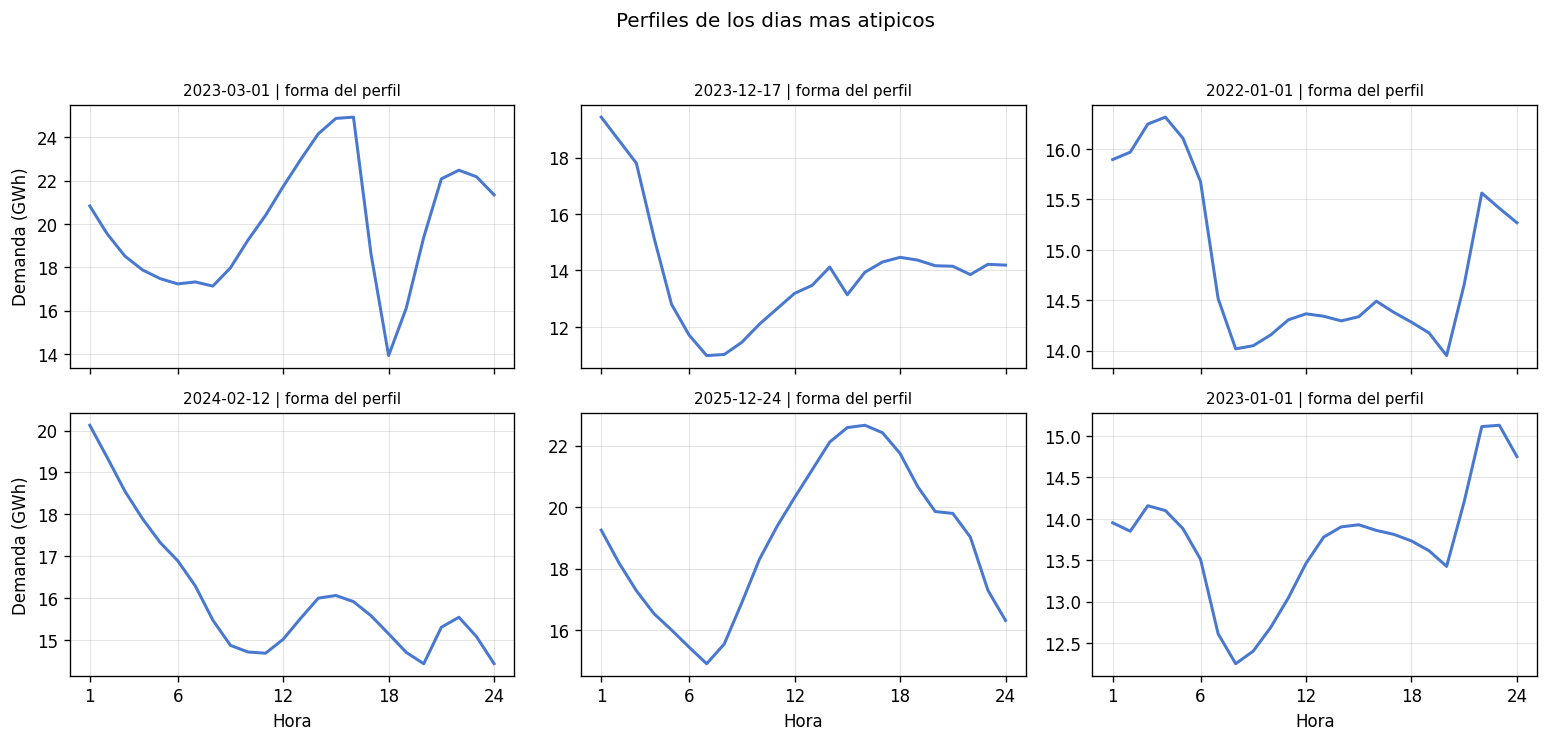

In [ ]:
plot_top_outlier_profiles(outlier_features)


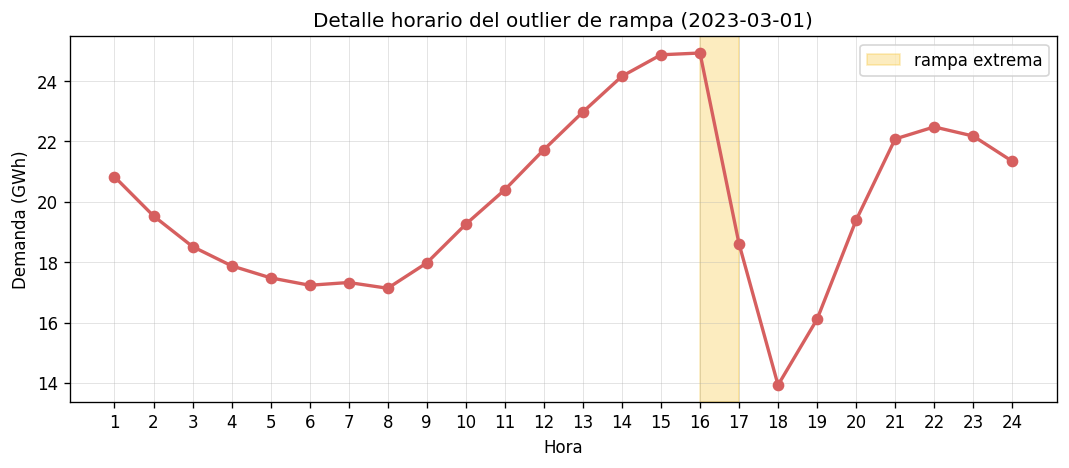

In [ ]:
plot_ramp_outlier_detail(outlier_features, date="2023-03-01")


El ranking por score total confirma que 2023-03-01 es un caso aparte. La rampa extrema ocurre entre las horas 16 y 17, con una caida de 6.320,5 MWh, seguida por otra caida hacia la hora 18 y recuperacion posterior. El dia tambien fue caluroso, pero el calor explica el nivel alto previo, no la caida brusca. Por eso lo clasificamos como evento de suministro y conviene etiquetarlo aparte. Este patron coincide con reportes publicos de un apagón masivo en Argentina ese mismo dia, durante una ola de calor.

Tambien aparecen varios perfiles con forma atipica por tener pico en hora 1, 4 o 14. Algunos son claramente fechas especiales, como Año Nuevo, Nochebuena o fin de año. Otros, como 2023-02-16 y 2022-02-11, no tienen una explicacion tan clara y quedan como candidatos a revision. No necesariamente son errores, pero si pueden afectar un modelo generativo si se entrenan sin etiqueta.

La distribucion de hora pico ayuda a separar lo raro de lo esperable: las horas 21 y 22 explican 75,5% de los dias, y la hora 16 explica 13,6%, sobre todo en verano. En cambio, picos en hora 4, 13 o 20 son muy infrecuentes. La hora 1 aparece en 41 dias; no es imposible, pero suele venir asociada a perfiles con forma especial o a efectos de borde entre dias.


### Preguntas a responder

**Hay outliers que deberian conservarse porque representan variabilidad real?**  
Si. Los extremos altos de energia y demanda maxima corresponden principalmente a dias de calor extremo, como 2024-02-01 y 2025-02-10. Los extremos bajos, como 2022-12-25, se explican por calendario especial. Estos casos representan variabilidad real del sistema y deberian conservarse, siempre que el modelo reciba condiciones de clima y calendario.

**Hay outliers que parecen errores de datos?**  
No aparecen valores imposibles ni un patron claro de error de medicion. El caso mas sospechoso es 2023-03-01, pero no necesariamente es un error: parece un evento real de suministro o corte masivo. La recomendacion no es borrarlo automaticamente, sino etiquetarlo aparte y revisar si conviene incluirlo segun el objetivo del modelo.

**El modelo deberia aprender esos dias o conviene etiquetarlos aparte?**  
Los outliers explicables por clima y calendario deberian aprenderse, porque son parte del comportamiento real que el generador debe reproducir. Los outliers por eventos de suministro, rampas extremas o formas horarias raras sin explicacion clara conviene etiquetarlos aparte. Para el entrenamiento principal se puede probar con y sin esos dias y evaluar si degradan la calidad de perfiles sinteticos normales.


## 11. Preguntas finales del EDA

**¿La demanda está más explicada por calendario, clima o tendencia temporal?**  
El calendario y el clima son los factores dominantes. El tipo de día explica 
diferencias de hasta 14,5% en el nivel de consumo y cambia la forma del perfil 
horario. El clima, capturado principalmente por `grado_calor` (r = 0,647), 
explica los extremos de nivel y el doble pico de los días de verano. La 
tendencia temporal es leve — la mediana anual creció unos 20 GWh entre 2021 
y 2025 — y no requiere modelado explícito.

**¿La forma diaria cambia mucho o cambia principalmente el nivel?**  
Ambos cambian, pero el nivel domina en los datos crudos: PC1 explica el 86,5% 
de la varianza y tiene correlación 0,999 con la energía diaria. La forma sí 
cambia de manera sistemática según el tipo de día (meseta diurna en hábiles 
vs. único pico nocturno en domingos) y según la estación (doble pico en verano 
vs. pico nocturno en invierno). Modelar solo el nivel sería insuficiente.

**¿Hay una tendencia creciente o decreciente entre 2021 y 2026?**  
Hay una tendencia creciente leve y sostenida. El año 2021 queda alrededor de 
3% por debajo de años comparables, con una normalización progresiva hacia 2022 
y 2023. Desde 2023 la demanda se estabiliza con una leve suba. La tendencia 
no es lo suficientemente pronunciada como para requerir una variable de año 
en el modelo, pero conviene mencionarla como limitación.

**¿El año 2021 se comporta distinto por pandemia y reapertura?**  
Sí, principalmente en nivel. Contra días comparables de años posteriores, 
2021 queda aproximadamente 3% por debajo tanto en días hábiles como en fines 
de semana. No aparece una forma horaria nueva sino una demanda general algo 
deprimida. El efecto es más pronunciado en la ventana de aislamiento estricto 
de mayo de 2021, donde los días hábiles caen 4% contra controles comparables.

**¿Los feriados argentinos tienen un patrón propio?**  
Los feriados se comportan de manera muy similar a los domingos, con energía 
media de 346.000 MWh vs. 339.000 MWh de los domingos. La forma del perfil 
horario es prácticamente idéntica: sin meseta diurna y con único pico nocturno. 
Para el modelo, pueden tratarse como categoría separada dentro de `tipo_dia` 
pero reconociendo su similitud con el domingo.

**¿Los domingos y feriados son parecidos?**  
Sí. La diferencia en energía media es de menos del 2% y los perfiles horarios 
son casi indistinguibles. La principal diferencia es que algunos feriados que 
caen en fechas especiales (Navidad, Año Nuevo) tienen niveles aún más bajos, 
mientras que los domingos son más uniformes entre sí.

**¿El calor afecta más que el frío, o ambos importan?**  
Ambos importan, pero el calor tiene mayor impacto. `grado_calor` tiene 
correlación de 0,647 con la energía diaria, mientras que `grado_frio` llega 
a 0,326. Además, el calor modifica la forma del perfil generando un pico de 
mediodía que el frío no produce.

**¿La temperatura afecta igual a todas las horas?**  
No. En días calurosos el pico de mediodía aparece entre las 13 y 16 hs, 
mientras que la madrugada se comporta de manera similar a días templados. 
En días fríos el efecto es más uniforme a lo largo del día. Esto sugiere 
que el clima horario podría aportar información adicional, aunque el clima 
diario agregado es una simplificación razonable para empezar.

**¿La sensación térmica explica mejor la demanda que la temperatura?**  
Marginalmente (r = 0,187 vs. r = 0,171 con energía diaria), pero la 
diferencia es pequeña. Las variables `grado_calor` y `grado_frio`, que 
capturan el efecto no lineal, son mejores predictores que cualquiera de 
las dos en forma directa.

**¿Hay eventos sociales que generen días atípicos?**  
Sí, pero con matices. La final del Mundial 2022 muestra una caída de 6,45% 
contra domingos comparables, el efecto más claro de todos los eventos 
analizados. Las elecciones de 2023 muestran resultados mixtos: PASO y 
elección general quedan 5-6% por encima de controles, pero el balotaje 
queda normal. El día de festejos del 20/12/2022 no aparece como outlier. 
En todos los casos el efecto del clima dificulta el aislamiento del evento.

**¿Conviene excluir, conservar o etiquetar días excepcionales?**  
Los outliers explicables por clima extremo y calendario especial deben 
conservarse: representan variabilidad real que el modelo debe aprender si 
recibe las condiciones correctas. El caso 2023-03-01, con rampa y amplitud 
extremas sin explicación climática clara, conviene etiquetarlo aparte y 
evaluar su efecto en el entrenamiento. No se identificaron errores de 
medición claros en el dataset.

**¿Qué variables deberían entrar al vector condicional C?**  
En base al EDA, el vector condicional mínimo viable es:
- `tipo_dia`: captura la estructura horaria (hábil, sábado, domingo, feriado)
- `mes`: captura la estacionalidad de nivel y la forma del pico estacional
- `grado_calor`: captura el efecto no lineal del calor sobre la demanda
- `grado_frio`: captura el efecto no lineal del frío sobre la demanda

Variables como humedad, viento y amplitud térmica tienen correlaciones 
bajas y no justifican su inclusión en una primera versión del modelo.

**¿Qué métricas deberían usarse para evaluar datos generados?**  
Ver paso 12.

## 12. Resultado esperado del EDA

### Descripción del dataset

El dataset cubre 1.946 días entre enero de 2021 y abril de 2026, con 24 
valores horarios de demanda eléctrica por día en MWh. Está completo, sin 
fechas faltantes, horas duplicadas ni valores nulos. Los rangos de todas 
las variables son plausibles. El empalme entre las dos fuentes originales 
no introduce un salto artificial detectable.

### Patrones principales

La demanda diaria está estructurada por tres factores principales:

- **Tipo de día**: los días hábiles consumen en promedio 14,5% más que los 
domingos y tienen una forma de perfil distinta, con meseta diurna entre 
las 10 y las 18 hs. Domingos y feriados comparten forma y nivel.
- **Estacionalidad**: enero, febrero, junio y julio son los meses de mayor 
demanda. La forma del pico cambia entre verano (pico de tarde por aire 
acondicionado) e invierno (único pico nocturno).
- **Clima**: la relación entre temperatura y demanda tiene forma de U con 
mínimo alrededor de 18-20 °C. El calor tiene mayor impacto que el frío 
(`grado_calor` r = 0,647 vs. `grado_frio` r = 0,326).

### Variables útiles para el modelo condicional

| Variable | Justificación |
|---|---|
| `tipo_dia` | Determina la forma del perfil horario |
| `mes` | Captura estacionalidad de nivel y forma del pico |
| `grado_calor` | Efecto no lineal del calor, mayor correlación climática |
| `grado_frio` | Efecto no lineal del frío |

### Días atípicos relevantes

| Fecha | Tipo | Decisión recomendada |
|---|---|---|
| 2024-02-01 | Calor extremo, máximo histórico | Conservar |
| 2022-12-25 | Navidad, mínimo histórico | Conservar |
| 2023-03-01 | Rampa y amplitud extremas sin explicación climática | Etiquetar aparte |
| 2022-12-18 | Final del Mundial, -6,45% vs. domingos comparables | Conservar con etiqueta |
| Mayo 2021 | Aislamiento estricto, días hábiles -4% | Conservar |

### Decisión sobre nivel y forma

El modelo debe aprender ambas cosas. El nivel explica el 86,5% de la 
varianza en datos crudos pero la forma cambia de manera sistemática según 
el tipo de día y la estación. Ignorar la forma produciría perfiles suavizados 
que no reproducirían el doble pico de verano ni la meseta diurna de los días 
hábiles. Se recomienda evaluar el modelo tanto en valores absolutos como en 
perfiles normalizados por energía diaria.

### Métricas para evaluar perfiles generados

Para comparar perfiles reales contra perfiles sintéticos se recomienda usar:

- **Perfil horario promedio por grupo**: comparar la curva media de datos 
reales vs. generados, segmentada por tipo de día y mes. Es la verificación 
más directa de que el modelo aprendió la forma correcta.
- **Distribución de energía diaria total**: comparar histogramas o densidades 
de la energía diaria para verificar que el modelo no colapse a la media.
- **Distribución de hora pico**: verificar que el modelo reproduce la 
concentración en hora 21 en días no estivales y la bimodalidad en verano.
- **Distribución de amplitud diaria**: verificar que el modelo genera perfiles 
con variación intradiaria realista y no curvas planas.
- **Banda p25-p75 por hora**: comparar la dispersión horaria real vs. generada. 
Un modelo que genera varianza insuficiente producirá bandas más estrechas 
que las reales.
- **Correlación condición-perfil**: verificar que los perfiles generados bajo 
distintas condiciones (hábil vs. domingo, verano vs. invierno) se diferencian 
de la misma manera que en los datos reales.

MSE o MAE solos son insuficientes para evaluar un modelo generativo: un modelo 
que siempre genere el perfil promedio tendría MSE bajo pero no capturaría la 
variabilidad real del sistema.